# Eleições 2026 — Presidente, 1º e 2º turno

Fonte: resultados por seção eleitoral do TSE (Dados Abertos), arquivo nacional `BR` (Presidente) de `votacao_secao_2026`.

CSV em `../data/votacao_secao_2026_BR.csv` — separador `;`, encoding `latin1`, uma linha por seção × candidato.

## Aviso importante sobre o escopo desta análise

Esta é uma análise estatística dos **dados abertos exatamente como o TSE os publicou** — nada além disso. Ela testa a consistência interna desses dados (os números batem entre si? os padrões encontrados fazem sentido geográfico/demográfico? alguma alegação específica de fraude é compatível com o que os números mostram?). Ela **não** é, e não pretende ser:

- Uma atestação de que os dados abertos divulgados pelo TSE não foram alterados, de alguma forma, antes da divulgação;
- Uma atestação de que a logística da eleição (preparação de urnas, transmissão, apuração) ocorreu sem falha, fraude ou irregularidade fora do que é capturado nesses dados;
- Uma certificação de lisura do processo eleitoral como um todo.

A ausência de anomalia estatística nos dados divulgados não resolve a pergunta de se esses dados são, eles mesmos, um retrato fiel do que aconteceu nas urnas — essa é uma pergunta sobre a qual dado aberto, por definição, não tem como se pronunciar, porque ela está logicamente a montante do próprio dado. Não estamos afirmando que tudo funcionou perfeitamente bem; estamos afirmando que, **dentro do que os dados abertos disponibilizados permitem verificar**, as alegações específicas testadas abaixo não se sustentam.

In [1]:
import duckdb
import pandas as pd

con = duckdb.connect()
con.execute("PRAGMA disable_progress_bar")
CSV_PATH = "../data/votacao_secao_2026_BR.csv"

## Visão geral: colunas e volume

In [2]:
con.sql(f"""
    SELECT *
    FROM read_csv('{CSV_PATH}', delim=';', encoding='latin1', header=True)
    LIMIT 5
""").df()

,DT_GERACAO,HH_GERACAO,ANO_ELEICAO,CD_TIPO_ELEICAO,NM_TIPO_ELEICAO,NR_TURNO,CD_ELEICAO,DS_ELEICAO,DT_ELEICAO,TP_ABRANGENCIA,...,NR_SECAO,CD_CARGO,DS_CARGO,NR_VOTAVEL,NM_VOTAVEL,QT_VOTOS,NR_LOCAL_VOTACAO,SQ_CANDIDATO,NM_LOCAL_VOTACAO,DS_LOCAL_VOTACAO_ENDERECO
0,2026-10-26,12:07:25,2026,2,Eleição Ordinária,1,6257,Eleição Geral Federal 2026,2026-10-04,False,...,554,1,Presidente,55,RONALDO RAMOS CAIADO,3,1910,280002551932,ESCOLA MUNICIPAL MARIA LEAL,POVOADO CAPINAL - ZONA RURAL
1,2026-10-26,12:07:25,2026,2,Eleição Ordinária,1,6257,Eleição Geral Federal 2026,2026-10-04,False,...,144,1,Presidente,55,RONALDO RAMOS CAIADO,1,1473,280002551932,GRUPO ESCOLAR ISIDORO ARAGAO GUERRA,"RUA LUTHGARDES NOGUEIRA, S/N - ZONA URBANA"
2,2026-10-26,12:07:25,2026,2,Eleição Ordinária,1,6257,Eleição Geral Federal 2026,2026-10-04,False,...,112,1,Presidente,55,RONALDO RAMOS CAIADO,1,1023,280002551932,COLÉGIO ESTADUAL DE TEMPO INTEGRAL NOVIS FILHO,"RUA ANTONIO GUIMARÃES, 485 - ZONA URBANA"
3,2026-10-26,12:07:25,2026,2,Eleição Ordinária,1,6257,Eleição Geral Federal 2026,2026-10-04,False,...,230,1,Presidente,55,RONALDO RAMOS CAIADO,1,1139,280002551932,ESCOLA MUNICIPAL ANTONIO CAMARA RIBEIRO,"RUA PRINCIPAL, ZONA RURAL - NOVA BRASÍLIA"
4,2026-10-26,12:07:25,2026,2,Eleição Ordinária,1,6257,Eleição Geral Federal 2026,2026-10-04,False,...,20,1,Presidente,55,RONALDO RAMOS CAIADO,3,1023,280002551932,ESCOLA JOSÉ PONCIANO DO NASCIMENTO,"RUA SÃO ROQUE, S/N - ZONA URBANA"


In [3]:
con.sql(f"""
    SELECT NR_TURNO, COUNT(*) AS linhas, COUNT(DISTINCT SG_UF) AS ufs
    FROM read_csv('{CSV_PATH}', delim=';', encoding='latin1', header=True)
    GROUP BY NR_TURNO
    ORDER BY NR_TURNO
""").df()

,NR_TURNO,linhas,ufs
0,1,3800511,28
1,2,1931103,28


## Totais nacionais por candidato e turno

In [4]:
totais_candidato = con.sql(f"""
    SELECT
        NR_TURNO,
        NR_VOTAVEL,
        NM_VOTAVEL,
        SUM(QT_VOTOS) AS total_votos
    FROM read_csv('{CSV_PATH}', delim=';', encoding='latin1', header=True)
    GROUP BY NR_TURNO, NR_VOTAVEL, NM_VOTAVEL
    ORDER BY NR_TURNO, total_votos DESC
""").df()

totais_candidato

,NR_TURNO,NR_VOTAVEL,NM_VOTAVEL,total_votos
0,1,22,FLAVIO NANTES BOLSONARO,56104503.0
1,1,13,LUIZ INÁCIO LULA DA SILVA,53879538.0
2,1,96,VOTO NULO,3669003.0
3,1,70,AUGUSTO JORGE CURY,3448569.0
4,1,14,RENAN ANTONIO FERREIRA DOS SANTOS,2675887.0
5,1,55,RONALDO RAMOS CAIADO,2605148.0
6,1,95,VOTO BRANCO,2300798.0
7,1,30,ROMEU ZEMA NETO,326488.0
8,1,80,SAMARA MARTINS DA SILVA FEITOSA,122911.0
9,1,16,HERTZ DA CONCEICAO DIAS,43103.0


## Totais por UF e turno (base para mapa/comparação estadual)

In [5]:
totais_uf = con.sql(f"""
    SELECT
        SG_UF,
        NR_TURNO,
        NR_VOTAVEL,
        NM_VOTAVEL,
        SUM(QT_VOTOS) AS total_votos
    FROM read_csv('{CSV_PATH}', delim=';', encoding='latin1', header=True)
    GROUP BY SG_UF, NR_TURNO, NR_VOTAVEL, NM_VOTAVEL
    ORDER BY SG_UF, NR_TURNO, total_votos DESC
""").df()

totais_uf.head(20)

,SG_UF,NR_TURNO,NR_VOTAVEL,NM_VOTAVEL,total_votos
0,AC,1,22,FLAVIO NANTES BOLSONARO,302807.0
1,AC,1,13,LUIZ INÁCIO LULA DA SILVA,134770.0
2,AC,1,96,VOTO NULO,13662.0
3,AC,1,70,AUGUSTO JORGE CURY,13523.0
4,AC,1,55,RONALDO RAMOS CAIADO,8594.0
5,AC,1,14,RENAN ANTONIO FERREIRA DOS SANTOS,7980.0
6,AC,1,95,VOTO BRANCO,5579.0
7,AC,1,30,ROMEU ZEMA NETO,573.0
8,AC,1,80,SAMARA MARTINS DA SILVA FEITOSA,314.0
9,AC,1,27,CLARIANA ZACARKIM BARAO,215.0


## 2º turno — ocorrências operacionais (prorrogação e contingência de urna)

Fonte: **Boletim de Urna Web** (`../data/bu_web_2t/*.csv`), granularidade de urna/seção — só existe para o 2º turno (único turno com prorrogação em 2026). Ver `docs/tse_dados_abertos.md` para o dicionário de campos completo.

Foco principal: seções com horário de encerramento atípico (candidatas a prorrogação). Secundário: agregação de seção e abertura atípica (indícios de contingência de urna).

In [6]:
BU_PATH = "../data/bu_web_2t/*.csv"

# Uma linha por seção (colapsando as linhas repetidas por candidato)
secoes_bu = con.sql(f"""
    SELECT DISTINCT
        SG_UF, NM_MUNICIPIO, NR_ZONA, NR_SECAO,
        DT_ABERTURA, DT_ENCERRAMENTO, DS_SECOES_AGREGADAS
    FROM read_csv('{BU_PATH}', delim=';', encoding='latin1', header=True, union_by_name=True)
""")
con.register("secoes_bu", secoes_bu.df())

print(con.sql("SELECT COUNT(*) AS total_secoes FROM secoes_bu").df())

   total_secoes
0        499207


### Prorrogação do horário de encerramento (foco principal)

Em vez de uma tabela fixa de fuso horário por UF (que tem exceções difíceis de mapear, como os ~11 municípios do sudoeste do Amazonas que seguem o fuso do Acre), a detecção usa a própria distribuição dos dados: calcula a mediana do horário de encerramento de cada UF e marca como atípica qualquer seção que fechou mais de 30 minutos depois disso.

Nota: o TSE reportou ~24.268 seções abertas depois das 17h10 (horário de Brasília) nacionalmente. Nosso número vai ser diferente porque a metodologia é outra (desvio da mediana de cada UF, não um corte absoluto único) — é esperado, não é erro.

In [7]:
baseline_horarios = con.sql("""
    SELECT
        SG_UF,
        MEDIAN(EXTRACT(EPOCH FROM (DT_ABERTURA - DATE_TRUNC('day', DT_ABERTURA)))) AS mediana_abertura_seg,
        MEDIAN(EXTRACT(EPOCH FROM (DT_ENCERRAMENTO - DATE_TRUNC('day', DT_ENCERRAMENTO)))) AS mediana_encerramento_seg
    FROM secoes_bu
    GROUP BY SG_UF
""")
con.register("baseline_horarios", baseline_horarios.df())

prorrogacao_por_uf = con.sql("""
    SELECT
        s.SG_UF,
        COUNT(*) AS secoes_com_prorrogacao
    FROM secoes_bu s
    JOIN baseline_horarios b USING (SG_UF)
    WHERE EXTRACT(EPOCH FROM (s.DT_ENCERRAMENTO - DATE_TRUNC('day', s.DT_ENCERRAMENTO))) - b.mediana_encerramento_seg > 1800
    GROUP BY s.SG_UF
    ORDER BY secoes_com_prorrogacao DESC
""").df()

print(f"Total nacional de seções com encerramento atípico: {prorrogacao_por_uf['secoes_com_prorrogacao'].sum()}")
prorrogacao_por_uf

Total nacional de seções com encerramento atípico: 7555


,SG_UF,secoes_com_prorrogacao
0,RJ,3312
1,SP,1960
2,BA,1041
3,PE,717
4,PB,316
5,SE,55
6,DF,24
7,PA,17
8,MG,16
9,CE,14


### Secundário: contingência de urna

Dois mecanismos distintos (ver `docs/tse_dados_abertos.md`):
- **Agregação de seção** (`DS_SECOES_AGREGADAS` preenchido): a urna quebrou sem reposição a tempo, e os eleitores foram redirecionados pra outra seção já funcionando. Confirmado diretamente nos dados.
- **Abertura atípica**: a urna abriu bem depois do normal naquela UF — indício de que algo aconteceu com ela (pode ser troca de contingência ativada depois, atraso de mesário, etc.). É um sinal indireto, não confirma troca de urna por si só — não há dataset aberto do TSE que registre qual urna era a planejada pra cada seção, pra confirmar troca de hardware com certeza.

In [8]:
agregacao_por_uf = con.sql("""
    SELECT SG_UF, COUNT(*) AS secoes_agregadoras
    FROM secoes_bu
    WHERE DS_SECOES_AGREGADAS != '#NULO#'
    GROUP BY SG_UF
    ORDER BY secoes_agregadoras DESC
""").df()

print(f"Total nacional de seções com agregação: {agregacao_por_uf['secoes_agregadoras'].sum()}")
agregacao_por_uf.head(10)

Total nacional de seções com agregação: 16142


,SG_UF,secoes_agregadoras
0,BA,2198
1,MG,1876
2,CE,1656
3,MA,1487
4,ZZ,1216
5,PA,1093
6,RJ,1007
7,PI,954
8,PE,626
9,MT,595


### Classificação final por seção (`TIPO_OCORRENCIA_SECAO`)

Uma coluna categórica por seção, combinando os três sinais acima, priorizando do mais específico pro mais genérico.

In [9]:
classificacao_secoes = con.sql("""
    WITH flags AS (
        SELECT
            s.SG_UF, s.NM_MUNICIPIO, s.NR_ZONA, s.NR_SECAO,
            s.DT_ABERTURA, s.DT_ENCERRAMENTO, s.DS_SECOES_AGREGADAS,
            (s.DS_SECOES_AGREGADAS != '#NULO#') AS flag_agregada,
            (EXTRACT(EPOCH FROM (s.DT_ENCERRAMENTO - DATE_TRUNC('day', s.DT_ENCERRAMENTO))) - b.mediana_encerramento_seg > 1800) AS flag_prorrogacao,
            (EXTRACT(EPOCH FROM (s.DT_ABERTURA - DATE_TRUNC('day', s.DT_ABERTURA))) - b.mediana_abertura_seg > 1800) AS flag_abertura_atipica
        FROM secoes_bu s
        JOIN baseline_horarios b USING (SG_UF)
    )
    SELECT
        *,
        CASE
            WHEN flag_agregada AND flag_prorrogacao THEN 'Agregada e prorrogada'
            WHEN flag_agregada THEN 'Agregada (contingência)'
            WHEN flag_prorrogacao THEN 'Prorrogada'
            WHEN flag_abertura_atipica THEN 'Abertura atípica (possível contingência)'
            ELSE 'Normal'
        END AS tipo_ocorrencia_secao
    FROM flags
""").df()

con.register("classificacao_secoes", classificacao_secoes)

classificacao_secoes["tipo_ocorrencia_secao"].value_counts()

tipo_ocorrencia_secao
Normal                                      475290
Agregada (contingência)                      16064
Prorrogada                                    7477
Abertura atípica (possível contingência)       298
Agregada e prorrogada                           78
Name: count, dtype: int64

## Relatório visual — checagem de alegações virais e achados do 2º turno

Esta seção resume, em gráficos, os principais achados da checagem de três alegações virais sobre o 2º turno (prorrogação de horário, urnas trocadas/seções agregadas, votos sem biometria) e das anomalias encontradas ao longo da investigação (seções grandes/pequenas, concentração no RJ, etc.).

**Detalhamento completo, com todas as tabelas e ressalvas metodológicas, em `docs/checagem_alegacoes_virais_2t.md`.** Esta seção usa a metodologia rigorosa (fuso horário oficial por UF/município, não a mediana estatística das células acima) — por isso os números de prorrogação aqui são um pouco diferentes da classificação `tipo_ocorrencia_secao` feita mais acima.

In [10]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

# Paleta (categórica, validada contra daltonismo — ver skill de dataviz do projeto)
LULA, FLAVIO, MUTED, GRID, TEXT, INK = "#2a78d6", "#eb6834", "#898781", "#e1e0d9", "#52514e", "#0b0b0b"

plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": GRID,
    "axes.labelcolor": TEXT, "text.color": INK, "xtick.color": TEXT, "ytick.color": TEXT,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "font.size": 11,
    "axes.spines.top": False, "axes.spines.right": False,
})

def fmt_milhar(x, pos):
    return f"{x:,.0f}".replace(",", ".")

### Base de dados do relatório

Uma linha por seção, com o resultado de Presidente (Lula/Flávio/Nulo/Branco), tamanho da seção, falha de biometria e classificação de prorrogação pelo método rigoroso de fuso horário (17h de Brasília, ajustado para UTC-4/UTC-5 onde a lei prevê, com tolerância de 10 min — ver seção 1 do documento).

In [11]:
con.execute(f"""
CREATE OR REPLACE VIEW bu_full AS
SELECT * FROM read_csv('{BU_PATH}', delim=';', encoding='latin1',
    union_by_name=True, header=True, types={{'DT_ENCERRAMENTO':'VARCHAR'}})
""")

con.execute("""
CREATE OR REPLACE VIEW secao_full_sql AS
SELECT
    SG_UF, NM_MUNICIPIO, NR_ZONA, NR_SECAO,
    MAX(QT_APTOS) AS aptos,
    MAX(QT_COMPARECIMENTO) AS comparecimento,
    MAX(QT_ELEI_BIOM_SEM_HABILITACAO) AS biom_falha,
    MAX(DS_SECOES_AGREGADAS) AS agregadas,
    MAX(DT_ENCERRAMENTO) AS dt_encerramento,
    SUM(CASE WHEN DS_CARGO_PERGUNTA='Presidente' AND NM_VOTAVEL='LULA' THEN QT_VOTOS ELSE 0 END) AS lula,
    SUM(CASE WHEN DS_CARGO_PERGUNTA='Presidente' AND NM_VOTAVEL='FLAVIO BOLSONARO' THEN QT_VOTOS ELSE 0 END) AS flavio,
    SUM(CASE WHEN DS_CARGO_PERGUNTA='Presidente' AND NM_VOTAVEL='Nulo' THEN QT_VOTOS ELSE 0 END) AS nulo,
    SUM(CASE WHEN DS_CARGO_PERGUNTA='Presidente' AND NM_VOTAVEL='Branco' THEN QT_VOTOS ELSE 0 END) AS branco
FROM bu_full
GROUP BY SG_UF, NM_MUNICIPIO, NR_ZONA, NR_SECAO
""")

secao_full = con.sql("SELECT * FROM secao_full_sql").df()

# Classificação: prorrogação (fuso rigoroso), tamanho, agregação, exterior
AC_LIKE_MUNICIPIOS = {'AMATURÁ','ATALAIA DO NORTE','BENJAMIN CONSTANT','EIRUNEPÉ','ENVIRA','GUAJARÁ',
                      'IPIXUNA','ITAMARATI','JUTAÍ','TABATINGA','SÃO PAULO DE OLIVENÇA'}

ts = pd.to_datetime(secao_full['dt_encerramento'], format='%Y-%m-%d %H:%M:%S', errors='coerce')
secao_full['hora_encerramento'] = ts.dt.hour + ts.dt.minute/60 + ts.dt.second/3600

def limite_tolerancia(row):
    if row['SG_UF'] == 'AC' or (row['SG_UF'] == 'AM' and row['NM_MUNICIPIO'] in AC_LIKE_MUNICIPIOS):
        return 15 + 10/60
    if row['SG_UF'] in ('MT', 'MS', 'RO', 'RR', 'AM'):
        return 16 + 10/60
    return 17 + 10/60

secao_full['limite_tolerancia'] = secao_full.apply(limite_tolerancia, axis=1)
secao_full['is_prorrogada'] = secao_full['hora_encerramento'].notna() & (secao_full['hora_encerramento'] > secao_full['limite_tolerancia'])
secao_full['is_agregada'] = secao_full['agregadas'].notna() & (secao_full['agregadas'] != '#NULO#')
secao_full['is_zz'] = secao_full['SG_UF'] == 'ZZ'
secao_full['is_grande'] = secao_full['aptos'] > 400
secao_full['is_pequena'] = secao_full['aptos'] < 195
secao_full['taxa_biom_falha'] = np.where(secao_full['comparecimento'] > 0, 100.0*secao_full['biom_falha']/secao_full['comparecimento'], np.nan)
secao_full['taxa_bn'] = np.where(secao_full['comparecimento'] > 0, 100.0*(secao_full['nulo']+secao_full['branco'])/secao_full['comparecimento'], np.nan)

con.register("secao_full", secao_full)

LULA_NAC = secao_full['lula'].sum()
FLAVIO_NAC = secao_full['flavio'].sum()
MARGEM_NAC = LULA_NAC - FLAVIO_NAC
print(f"Lula: {LULA_NAC:,.0f}  Flávio: {FLAVIO_NAC:,.0f}  Margem: {MARGEM_NAC:,.0f}".replace(",", "."))
print(f"Seções: {len(secao_full)}  Prorrogadas: {secao_full['is_prorrogada'].sum()}  Agregadas (sem exterior): {(secao_full['is_agregada'] & ~secao_full['is_zz']).sum()}")

Lula: 64.256.232  Flávio: 59.826.041  Margem: 4.430.191
Seções: 499207  Prorrogadas: 13700  Agregadas (sem exterior): 14926


### As três alegações virais + seções grandes/pequenas: margem gerada vs. margem nacional

Para cada mecanismo testado, duas perguntas: (1) quanto esse recorte pende, em votos, a favor de Lula? (2) se excluíssemos esse recorte inteiramente do total nacional, quem ainda venceria?

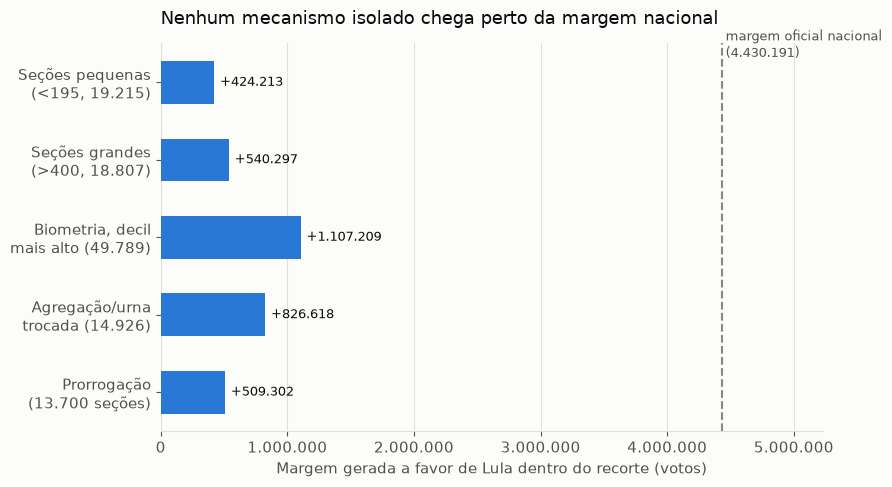

In [12]:
con.execute("""
CREATE OR REPLACE VIEW sub_decil_biom AS
SELECT *, NTILE(10) OVER (ORDER BY taxa_biom_falha) AS decil
FROM secao_full WHERE NOT is_zz AND comparecimento > 0 AND taxa_biom_falha IS NOT NULL
""")
decil10_biom = con.sql("SELECT * FROM sub_decil_biom WHERE decil=10").df()

grupos = {
    "Prorrogação\n(13.700 seções)": secao_full[secao_full.is_prorrogada],
    "Agregação/urna\ntrocada (14.926)": secao_full[secao_full.is_agregada & ~secao_full.is_zz],
    "Biometria, decil\nmais alto (49.789)": decil10_biom,
    "Seções grandes\n(>400, 18.807)": secao_full[secao_full.is_grande & ~secao_full.is_zz],
    "Seções pequenas\n(<195, 19.215)": secao_full[secao_full.is_pequena & ~secao_full.is_zz],
}

margens = [g['lula'].sum() - g['flavio'].sum() for g in grupos.values()]
labels = list(grupos.keys())

fig, ax = plt.subplots(figsize=(9, 5))
y = np.arange(len(labels))
ax.barh(y, margens, color=LULA, height=0.55, zorder=3)
ax.axvline(MARGEM_NAC, color=MUTED, linestyle="--", linewidth=1.5, zorder=2)
ax.text(MARGEM_NAC, len(labels)-0.3, f" margem oficial nacional\n ({MARGEM_NAC:,.0f})".replace(",", "."), color=TEXT, fontsize=9, va="top")
ax.set_yticks(y, labels)
ax.set_xlabel("Margem gerada a favor de Lula dentro do recorte (votos)")
ax.set_title("Nenhum mecanismo isolado chega perto da margem nacional", fontsize=13, color=INK, loc="left", pad=14)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(fmt_milhar))
for yi, v in zip(y, margens):
    ax.text(v + MARGEM_NAC*0.01, yi, f"+{v:,.0f}".replace(",", "."), va="center", fontsize=9.5, color=INK)
ax.set_xlim(0, MARGEM_NAC*1.18)
ax.grid(axis="y", visible=False)
fig.tight_layout()
plt.show()

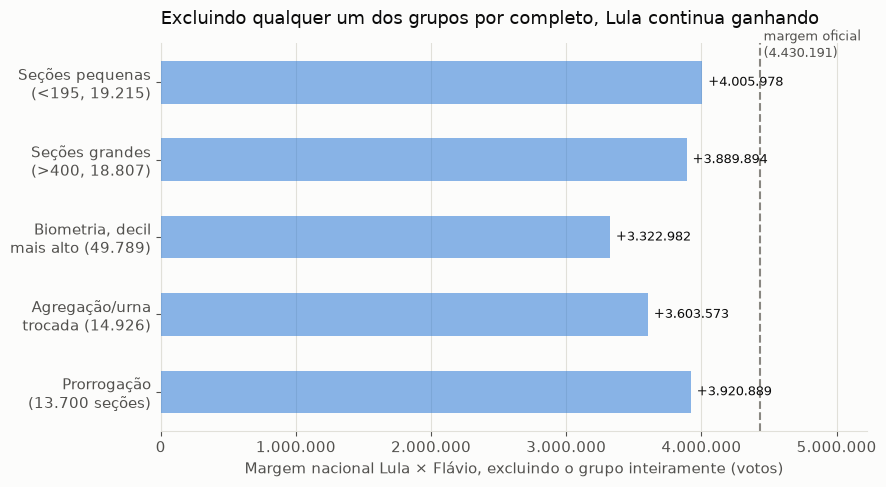

In [13]:
margens_excl = [(LULA_NAC - g['lula'].sum()) - (FLAVIO_NAC - g['flavio'].sum()) for g in grupos.values()]

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(y, margens_excl, color=LULA, height=0.55, zorder=3, alpha=0.55)
ax.axvline(MARGEM_NAC, color=MUTED, linestyle="--", linewidth=1.5, zorder=2)
ax.text(MARGEM_NAC, len(labels)-0.3, f" margem oficial\n ({MARGEM_NAC:,.0f})".replace(",", "."), color=TEXT, fontsize=9, va="top")
ax.set_yticks(y, labels)
ax.set_xlabel("Margem nacional Lula × Flávio, excluindo o grupo inteiramente (votos)")
ax.set_title("Excluindo qualquer um dos grupos por completo, Lula continua ganhando", fontsize=13, loc="left", pad=14)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(fmt_milhar))
for yi, v in zip(y, margens_excl):
    ax.text(v + MARGEM_NAC*0.01, yi, f"+{v:,.0f}".replace(",", "."), va="center", fontsize=9.5, color=INK)
ax.set_xlim(0, MARGEM_NAC*1.18)
ax.grid(axis="y", visible=False)
fig.tight_layout()
plt.show()

### Biometria por decil — a relação é real, mas pequena

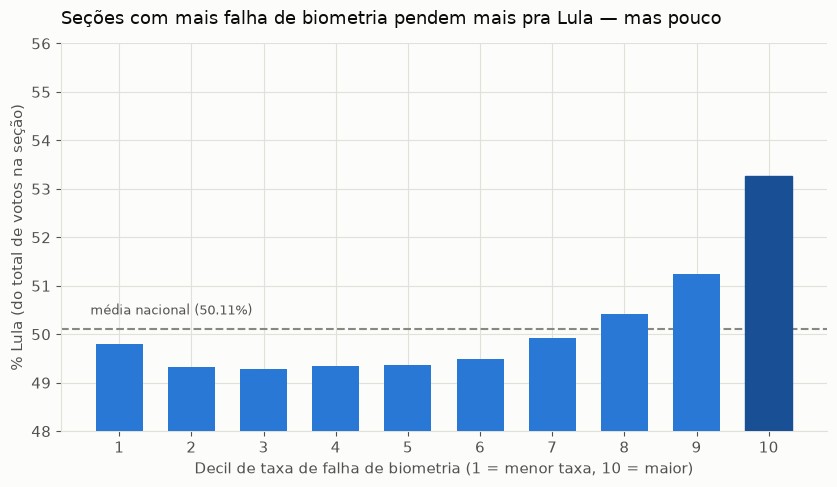

In [14]:
dec_tbl = con.sql("""
    SELECT decil, SUM(lula) lula, SUM(flavio) flavio, SUM(nulo) nulo, SUM(branco) branco
    FROM sub_decil_biom GROUP BY decil ORDER BY decil
""").df()
dec_tbl['pct_lula'] = 100*dec_tbl['lula']/(dec_tbl['lula']+dec_tbl['flavio']+dec_tbl['nulo']+dec_tbl['branco'])
pct_nac = 100*LULA_NAC/(LULA_NAC+FLAVIO_NAC+secao_full['nulo'].sum()+secao_full['branco'].sum())

fig, ax = plt.subplots(figsize=(8.5, 5))
bars = ax.bar(dec_tbl['decil'], dec_tbl['pct_lula'], color=LULA, width=0.65, zorder=3)
bars[-1].set_color("#184f95")
ax.axhline(pct_nac, color=MUTED, linestyle="--", linewidth=1.5, zorder=2)
ax.text(0.6, pct_nac+0.3, f"média nacional ({pct_nac:.2f}%)", color=TEXT, fontsize=9)
ax.set_xticks(dec_tbl['decil'])
ax.set_xlabel("Decil de taxa de falha de biometria (1 = menor taxa, 10 = maior)")
ax.set_ylabel("% Lula (do total de votos na seção)")
ax.set_title("Seções com mais falha de biometria pendem mais pra Lula — mas pouco", fontsize=13, loc="left", pad=14)
ax.set_ylim(48, 56)
fig.tight_layout()
plt.show()

### Outliers de seção dentro da própria zona eleitoral

Pra cada seção, calculamos o z-score do `% Lula` em relação à média/desvio-padrão da própria zona eleitoral (zonas com ≥15 seções, seções com ≥20 votos válidos) — procurando seções que destoam fortemente do padrão local, "parecendo não pertencer" à própria zona.

In [15]:
con.execute("""
CREATE OR REPLACE VIEW secao_pct AS
SELECT *, lula+flavio AS validos, 100.0*lula/(lula+flavio) AS pct_lula
FROM secao_full WHERE lula+flavio >= 20
""")
con.execute("""
CREATE OR REPLACE VIEW zona_stats AS
SELECT SG_UF, NM_MUNICIPIO, NR_ZONA, AVG(pct_lula) AS media_zona, STDDEV(pct_lula) AS std_zona, COUNT(*) AS n_secoes
FROM secao_pct GROUP BY SG_UF, NM_MUNICIPIO, NR_ZONA HAVING COUNT(*) >= 15
""")
outliers_zona = con.sql("""
    SELECT sp.*, zs.media_zona, zs.std_zona,
           (sp.pct_lula - zs.media_zona)/zs.std_zona AS zscore
    FROM secao_pct sp JOIN zona_stats zs USING (SG_UF, NM_MUNICIPIO, NR_ZONA)
    WHERE zs.std_zona > 0
""").df()

outliers_fortes = outliers_zona[outliers_zona['zscore'].abs() >= 3].copy()
n_pos = (outliers_fortes['zscore'] >= 3).sum()
n_neg = (outliers_fortes['zscore'] <= -3).sum()

margem_outliers = outliers_fortes['lula'].sum() - outliers_fortes['flavio'].sum()
margem_excl = (LULA_NAC - outliers_fortes['lula'].sum()) - (FLAVIO_NAC - outliers_fortes['flavio'].sum())

print(f"Seções elegíveis pro z-score (zona com >=15 seções): {len(outliers_zona):,}".replace(",", "."))
print(f"|z|>=3: {len(outliers_fortes)} seções ({n_pos} ilhas pró-Lula, {n_neg} ilhas pró-Flávio)")
print(f"Margem gerada dentro dos outliers: {margem_outliers:+,.0f}".replace(",", "."))
print(f"Margem nacional excluindo os outliers: {margem_excl:+,.0f} (oficial: {MARGEM_NAC:+,.0f})".replace(",", "."))

Seções elegíveis pro z-score (zona com >=15 seções): 488.048
|z|>=3: 2275 seções (1763 ilhas pró-Lula, 512 ilhas pró-Flávio)
Margem gerada dentro dos outliers: +103.428
Margem nacional excluindo os outliers: +4.326.763 (oficial: +4.430.191)


In [16]:
locais = con.sql(f"""
    SELECT DISTINCT SG_UF, NM_MUNICIPIO, NR_ZONA, NR_SECAO, NM_LOCAL_VOTACAO
    FROM read_csv('{CSV_PATH}', delim=';', encoding='latin1', header=True)
    WHERE DS_CARGO='Presidente' AND NR_TURNO=2
""").df()

top30 = outliers_zona.reindex(outliers_zona['zscore'].abs().sort_values(ascending=False).index).head(30)
top30 = top30.merge(locais, on=['SG_UF','NM_MUNICIPIO','NR_ZONA','NR_SECAO'], how='left')
top30[['SG_UF','NM_MUNICIPIO','NR_ZONA','NR_SECAO','NM_LOCAL_VOTACAO','lula','flavio','pct_lula','media_zona','zscore']].round(2)

,SG_UF,NM_MUNICIPIO,NR_ZONA,NR_SECAO,NM_LOCAL_VOTACAO,lula,flavio,pct_lula,media_zona,zscore
0,SP,MOGI GUAÇU,216,342,PENITENCIÁRIA FEMININA DE MOGI GUAÇU,174.0,9.0,95.08,31.58,11.87
1,SP,FRANCA,291,341,PENITENCIÁRIA DE FRANCA,41.0,3.0,93.18,38.93,9.50
2,SP,ITAPETININGA,52,233,POSTO AMBULATORIAL DE SAÚDE,61.0,12.0,83.56,33.49,9.18
3,SP,TAUBATÉ,141,409,"CDP DR. FÉLIX NOBRE DE CAMPOS, DE TAUBATÉ",27.0,4.0,87.10,36.17,9.15
4,SP,SÃO PAULO,248,887,UI-UNIDADE DE INTERNAÇÃO ITAQUERA - FUNDAÇÃO CASA,39.0,3.0,92.86,56.46,9.11
5,PA,ANANINDEUA,72,629,UNIDADE DE CUSTÓDIA E REINSERÇÃO FEMININA DE A...,31.0,3.0,91.18,50.82,9.08
6,GO,ANÁPOLIS,144,342,UNIDADE DE POLÍCIA PENAL REGIONAL DE ANÁPOLIS,30.0,11.0,73.17,27.50,8.27
7,DF,BRASÍLIA,21,354,UNIRE - UNIDADE DE INTERNAÇÃO DO RECANTO DAS EMAS,53.0,9.0,85.48,43.77,8.24
8,SP,SÃO PAULO,325,685,INTERNATO PIRITUBA,48.0,4.0,92.31,50.25,8.01
9,SP,VOTORANTIM,220,270,PENITENCIÁRIA FEMININA DE VOTORANTIM,67.0,9.0,88.16,40.52,7.96


In [17]:
def categoriza_local(nome):
    if pd.isna(nome):
        return 'Sem nome'
    n = nome.upper()
    if any(k in n for k in ['PENITENCI', 'PRESIDIO', 'CADEIA', 'SOCIOEDUCATIV', 'CENTRO DE DETEN', 'UNIDADE DE INTERNA', 'PRISIONAL', ' CDP']):
        return 'Prisional/socioeducativo'
    if any(k in n for k in ['INDIGENA', 'ALDEIA', 'TEKOA']):
        return 'Indígena (nome explícito)'
    if any(k in n for k in ['UNIVERSI', 'CAMPUS']):
        return 'Universidade/campus'
    if any(k in n for k in ['QUARTEL', 'BATALH', 'EXERCITO', 'MARINHA', 'AERONAUTICA']):
        return 'Militar'
    return 'Sem categoria identificada por palavra-chave'

outliers_loc = outliers_fortes.merge(locais, on=['SG_UF','NM_MUNICIPIO','NR_ZONA','NR_SECAO'], how='left')
outliers_loc['categoria'] = outliers_loc['NM_LOCAL_VOTACAO'].apply(categoriza_local)
outliers_loc['direcao'] = np.where(outliers_loc['zscore'] >= 3, 'Pró-Lula', 'Pró-Flávio')

pd.crosstab(outliers_loc['categoria'], outliers_loc['direcao'])

direcao,Pró-Flávio,Pró-Lula
categoria,,
Indígena (nome explícito),0,52
Militar,2,1
Prisional/socioeducativo,1,67
Sem categoria identificada por palavra-chave,500,1610
Sem nome,2,9
Universidade/campus,7,24


### Limite de 400 eleitores por seção — e quem fica nas duas pontas

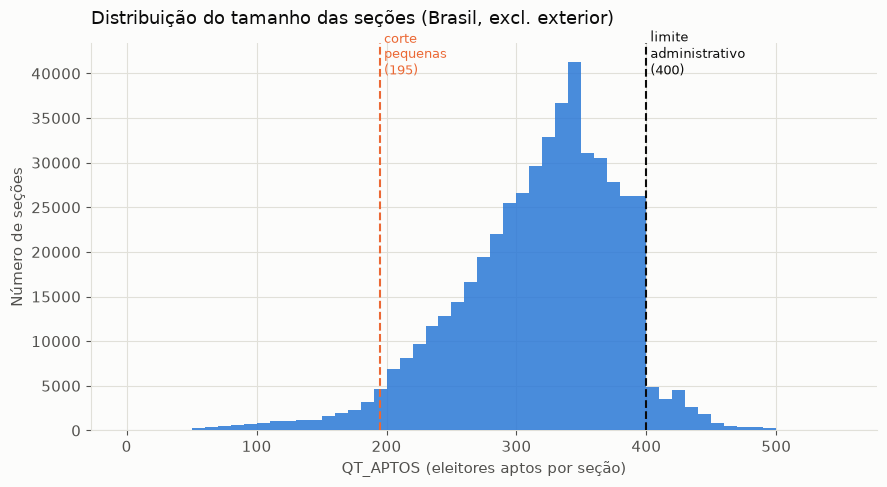

In [18]:
aptos = secao_full.loc[~secao_full.is_zz, 'aptos'].dropna()
fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(aptos, bins=np.arange(0, 560, 10), color=LULA, alpha=0.85, zorder=3)
ax.axvline(195, color=FLAVIO, linestyle="--", linewidth=1.5, zorder=4)
ax.axvline(400, color=INK, linestyle="--", linewidth=1.5, zorder=4)
ax.text(195, ax.get_ylim()[1]*0.92, " corte\n pequenas\n (195)", color=FLAVIO, fontsize=9)
ax.text(400, ax.get_ylim()[1]*0.92, " limite\n administrativo\n (400)", color=INK, fontsize=9)
ax.set_xlabel("QT_APTOS (eleitores aptos por seção)")
ax.set_ylabel("Número de seções")
ax.set_title("Distribuição do tamanho das seções (Brasil, excl. exterior)", fontsize=13, loc="left", pad=14)
fig.tight_layout()
plt.show()

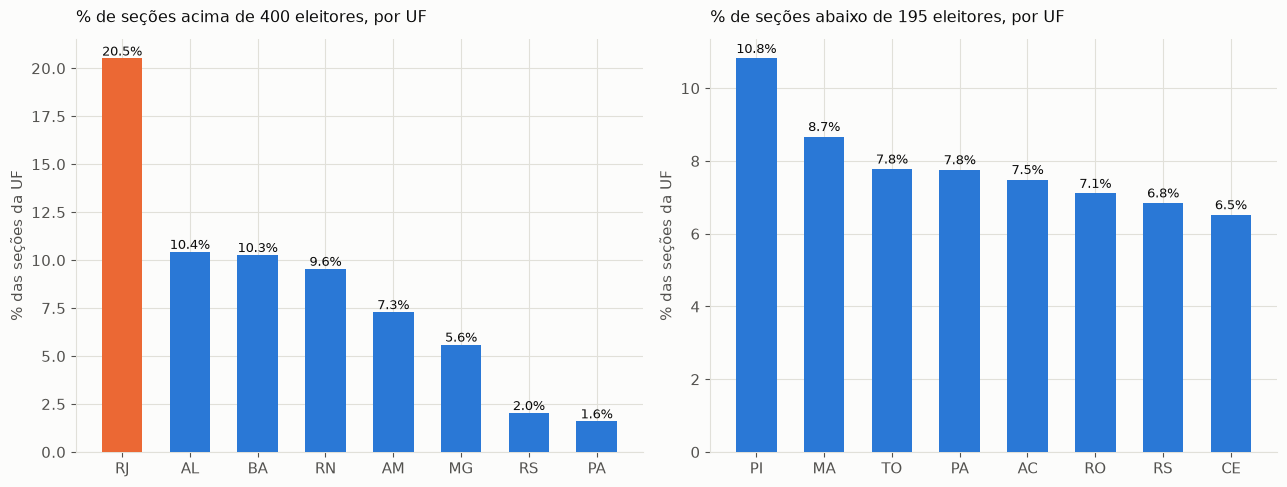

In [19]:
def uf_pct_table(flag_col):
    return con.sql(f"""
        WITH x AS (SELECT SG_UF, COUNT(*) AS n FROM secao_full WHERE NOT is_zz AND {flag_col} GROUP BY SG_UF),
             tot AS (SELECT SG_UF, COUNT(*) AS total FROM secao_full WHERE NOT is_zz GROUP BY SG_UF)
        SELECT x.SG_UF, x.n, tot.total, 100.0*x.n/tot.total AS pct
        FROM x JOIN tot USING (SG_UF)
        ORDER BY pct DESC LIMIT 8
    """).df()

t_grande = uf_pct_table("is_grande")
t_pequena = uf_pct_table("is_pequena")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, t, title in [(axes[0], t_grande, "% de seções acima de 400 eleitores, por UF"),
                      (axes[1], t_pequena, "% de seções abaixo de 195 eleitores, por UF")]:
    colors = [FLAVIO if uf == "RJ" else LULA for uf in t['SG_UF']]
    ax.bar(t['SG_UF'], t['pct'], color=colors, width=0.6, zorder=3)
    for i, v in enumerate(t['pct']):
        ax.text(i, v+0.15, f"{v:.1f}%", ha="center", fontsize=9, color=INK)
    ax.set_ylabel("% das seções da UF")
    ax.set_title(title, fontsize=11.5, loc="left", pad=12)
fig.tight_layout()
plt.show()

### Tamanho de seção × prorrogação, e o caso do RJ

Seções grandes prorrogam mais em qualquer lugar do país — mas isso não explica todo o excesso do RJ, que já prorroga mais que a média mesmo nas seções normais. E, controlando pela própria UF (não a média nacional), prorrogação não se inverte dentro do RJ.

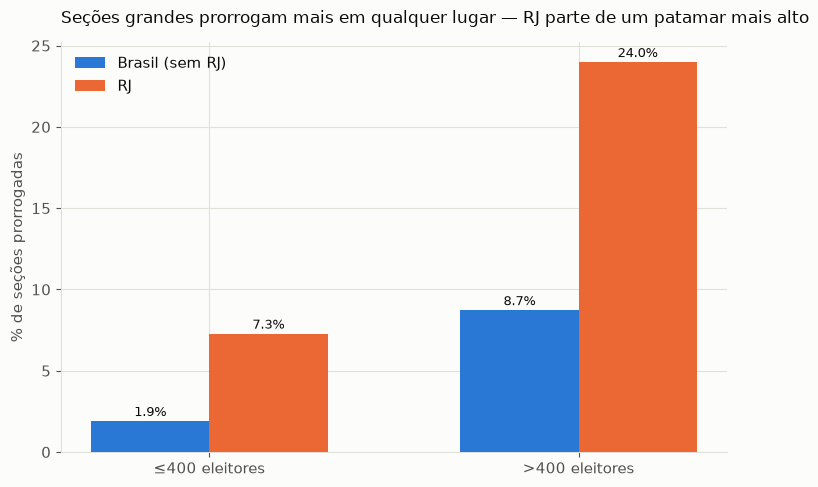

In [20]:
t = con.sql("""
    SELECT CASE WHEN SG_UF='RJ' THEN 'RJ' ELSE 'Brasil (sem RJ)' END AS grupo, is_grande,
        100.0*SUM(CASE WHEN is_prorrogada THEN 1 ELSE 0 END)/COUNT(*) AS pct_prorrogada
    FROM secao_full GROUP BY 1,2 ORDER BY 1,2
""").df()

fig, ax = plt.subplots(figsize=(7.5, 5))
x_labels = ["≤400 eleitores", ">400 eleitores"]
brasil_vals = t[t.grupo=="Brasil (sem RJ)"].sort_values("is_grande")["pct_prorrogada"].values
rj_vals = t[t.grupo=="RJ"].sort_values("is_grande")["pct_prorrogada"].values
x = np.arange(2); width = 0.32
ax.bar(x-width/2, brasil_vals, width, color=LULA, label="Brasil (sem RJ)", zorder=3)
ax.bar(x+width/2, rj_vals, width, color=FLAVIO, label="RJ", zorder=3)
for xi, v in zip(x-width/2, brasil_vals): ax.text(xi, v+0.3, f"{v:.1f}%", ha="center", fontsize=9.5)
for xi, v in zip(x+width/2, rj_vals): ax.text(xi, v+0.3, f"{v:.1f}%", ha="center", fontsize=9.5)
ax.set_xticks(x, x_labels)
ax.set_ylabel("% de seções prorrogadas")
ax.set_title("Seções grandes prorrogam mais em qualquer lugar — RJ parte de um patamar mais alto", fontsize=12, loc="left", pad=14)
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

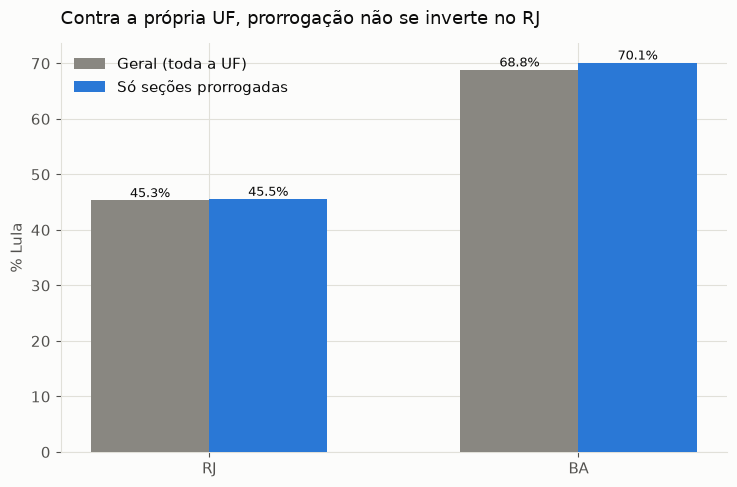

In [21]:
def pct_lula_geral_prorrogada(uf):
    geral = secao_full[secao_full.SG_UF == uf]
    pct_geral = 100*geral['lula'].sum()/(geral['lula'].sum()+geral['flavio'].sum()+geral['nulo'].sum()+geral['branco'].sum())
    prorr = secao_full[(secao_full.SG_UF == uf) & (secao_full.is_prorrogada)]
    pct_prorr = 100*prorr['lula'].sum()/(prorr['lula'].sum()+prorr['flavio'].sum()+prorr['nulo'].sum()+prorr['branco'].sum())
    return pct_geral, pct_prorr

rj_geral, rj_prorr = pct_lula_geral_prorrogada("RJ")
ba_geral, ba_prorr = pct_lula_geral_prorrogada("BA")

fig, ax = plt.subplots(figsize=(7.5, 5))
x = np.arange(2); width = 0.32
ax.bar(x-width/2, [rj_geral, ba_geral], width, color=MUTED, label="Geral (toda a UF)", zorder=3)
ax.bar(x+width/2, [rj_prorr, ba_prorr], width, color=LULA, label="Só seções prorrogadas", zorder=3)
for xi, v in zip(x-width/2, [rj_geral, ba_geral]): ax.text(xi, v+0.6, f"{v:.1f}%", ha="center", fontsize=9.5)
for xi, v in zip(x+width/2, [rj_prorr, ba_prorr]): ax.text(xi, v+0.6, f"{v:.1f}%", ha="center", fontsize=9.5)
ax.set_xticks(x, ["RJ", "BA"])
ax.set_ylabel("% Lula")
ax.set_title("Contra a própria UF, prorrogação não se inverte no RJ", fontsize=13, loc="left", pad=14)
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

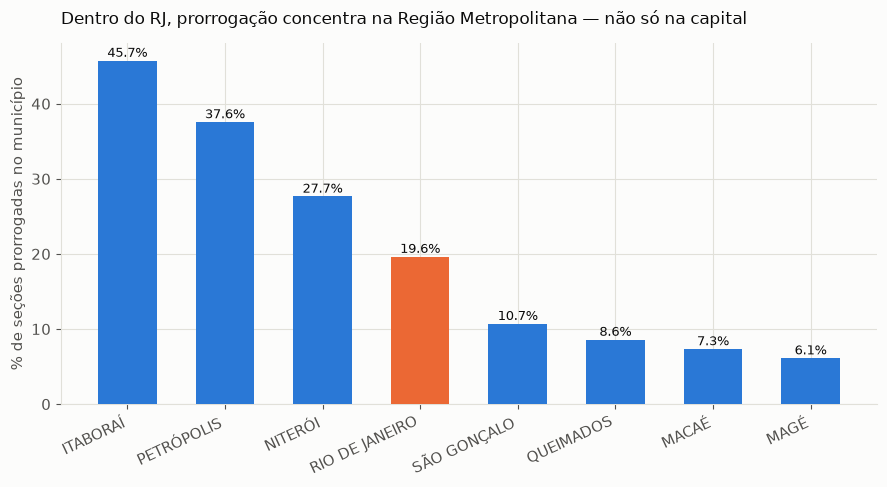

In [22]:
t = con.sql("""
    SELECT NM_MUNICIPIO, COUNT(*) AS total, 100.0*SUM(CASE WHEN is_prorrogada THEN 1 ELSE 0 END)/COUNT(*) AS pct
    FROM secao_full WHERE SG_UF='RJ'
    GROUP BY NM_MUNICIPIO HAVING COUNT(*) > 300
    ORDER BY pct DESC LIMIT 8
""").df()

fig, ax = plt.subplots(figsize=(9, 5))
colors = [FLAVIO if m == "RIO DE JANEIRO" else LULA for m in t['NM_MUNICIPIO']]
ax.bar(t['NM_MUNICIPIO'], t['pct'], color=colors, width=0.6, zorder=3)
for i, v in enumerate(t['pct']):
    ax.text(i, v+0.5, f"{v:.1f}%", ha="center", fontsize=9.5)
ax.set_ylabel("% de seções prorrogadas no município")
ax.set_title("Dentro do RJ, prorrogação concentra na Região Metropolitana — não só na capital", fontsize=12.5, loc="left", pad=14)
plt.setp(ax.get_xticklabels(), rotation=25, ha="right")
fig.tight_layout()
plt.show()

### Biometria e branco/nulo × tamanho de seção

Biometria: seções menores têm mais falha (correlação -0,17). Branco/nulo: o oposto, fraco e positivo (+0,105) — os dois fenômenos respondem a causas diferentes, não é um efeito genérico de "seção pequena é mais ruidosa".

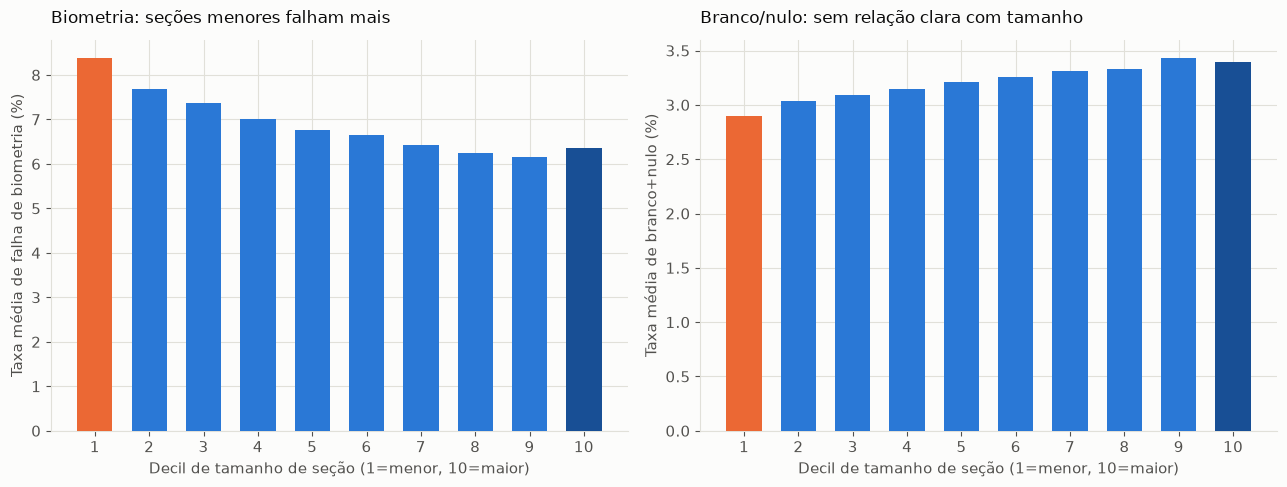

In [23]:
con.execute("""
CREATE OR REPLACE VIEW sub_decil_aptos AS
SELECT *, NTILE(10) OVER (ORDER BY aptos) AS decil_aptos
FROM secao_full WHERE NOT is_zz AND comparecimento > 0 AND taxa_biom_falha IS NOT NULL
""")
t = con.sql("""
    SELECT decil_aptos, MIN(aptos) amin, MAX(aptos) amax, AVG(taxa_biom_falha) taxa_biom, AVG(taxa_bn) taxa_bn
    FROM sub_decil_aptos GROUP BY decil_aptos ORDER BY decil_aptos
""").df()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ax = axes[0]
colors = [FLAVIO] + [LULA]*8 + ["#184f95"]
ax.bar(t['decil_aptos'], t['taxa_biom'], color=colors, width=0.65, zorder=3)
ax.set_xticks(t['decil_aptos'])
ax.set_xlabel("Decil de tamanho de seção (1=menor, 10=maior)")
ax.set_ylabel("Taxa média de falha de biometria (%)")
ax.set_title("Biometria: seções menores falham mais", fontsize=12, loc="left", pad=12)

ax = axes[1]
ax.bar(t['decil_aptos'], t['taxa_bn'], color=colors, width=0.65, zorder=3)
ax.set_xticks(t['decil_aptos'])
ax.set_xlabel("Decil de tamanho de seção (1=menor, 10=maior)")
ax.set_ylabel("Taxa média de branco+nulo (%)")
ax.set_title("Branco/nulo: sem relação clara com tamanho", fontsize=12, loc="left", pad=12)
fig.tight_layout()
plt.show()

### Governador: o efeito não se generaliza

Seis estados com 2º turno de Governador em 2026. Se prorrogação/agregação favorecesse mecanicamente quem já lidera (como pareceu acontecer com Lula no Presidente), o padrão deveria se repetir aqui — não se repete de forma uniforme.

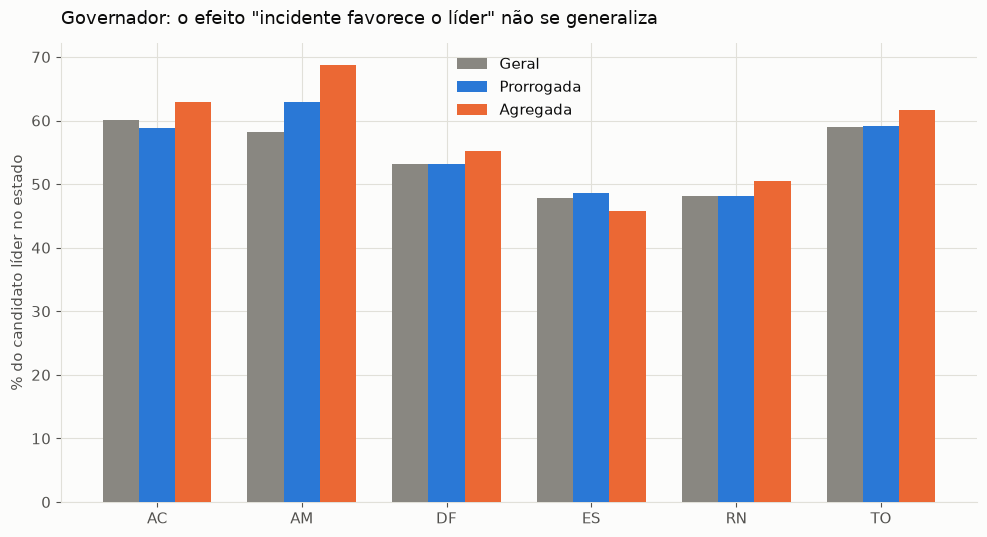

In [24]:
gov_ufs = ['AC', 'AM', 'DF', 'ES', 'RN', 'TO']
gov_lider = {'AC': 'MAILZA ASSIS', 'AM': 'OMAR AZIZ', 'DF': 'CELINA LEÃO',
             'ES': 'LORENZO PAZOLINI', 'RN': 'CADU DE LULA', 'TO': 'VICENTINHO JÚNIOR'}

gov_df = con.sql(f"""
    SELECT SG_UF, NM_MUNICIPIO, NR_ZONA, NR_SECAO, MAX(DS_SECOES_AGREGADAS) AS agregadas,
        MAX(DT_ENCERRAMENTO) AS dt_encerramento, NM_VOTAVEL, SUM(QT_VOTOS) AS votos
    FROM bu_full
    WHERE DS_CARGO_PERGUNTA = 'Governador' AND SG_UF IN ({','.join(f"'{u}'" for u in gov_ufs)})
    GROUP BY SG_UF, NM_MUNICIPIO, NR_ZONA, NR_SECAO, NM_VOTAVEL
""").df()

gov_df['ts'] = pd.to_datetime(gov_df['dt_encerramento'], format='%Y-%m-%d %H:%M:%S', errors='coerce')
gov_df['hora'] = gov_df['ts'].dt.hour + gov_df['ts'].dt.minute/60
gov_df['limite'] = gov_df.apply(limite_tolerancia, axis=1)
gov_df['is_prorrogada'] = gov_df['hora'] > gov_df['limite']
gov_df['is_agregada'] = gov_df['agregadas'].notna() & (gov_df['agregadas'] != '#NULO#')

rows = []
for uf, lider in gov_lider.items():
    sub = gov_df[gov_df.SG_UF == uf]
    def pct_lider(frame):
        total = frame['votos'].sum()
        return 100*frame[frame.NM_VOTAVEL == lider]['votos'].sum()/total if total else np.nan
    rows.append((uf, pct_lider(sub), pct_lider(sub[sub.is_prorrogada]), pct_lider(sub[sub.is_agregada])))
govt = pd.DataFrame(rows, columns=['UF', 'geral', 'prorrogada', 'agregada'])

fig, ax = plt.subplots(figsize=(10, 5.5))
x = np.arange(len(govt)); width = 0.25
ax.bar(x-width, govt['geral'], width, color=MUTED, label="Geral", zorder=3)
ax.bar(x, govt['prorrogada'], width, color=LULA, label="Prorrogada", zorder=3)
ax.bar(x+width, govt['agregada'], width, color=FLAVIO, label="Agregada", zorder=3)
ax.set_xticks(x, govt['UF'])
ax.set_ylabel("% do candidato líder no estado")
ax.set_title('Governador: o efeito "incidente favorece o líder" não se generaliza', fontsize=13, loc="left", pad=14)
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

### Exterior (ZZ): artefato estrutural, não contingência

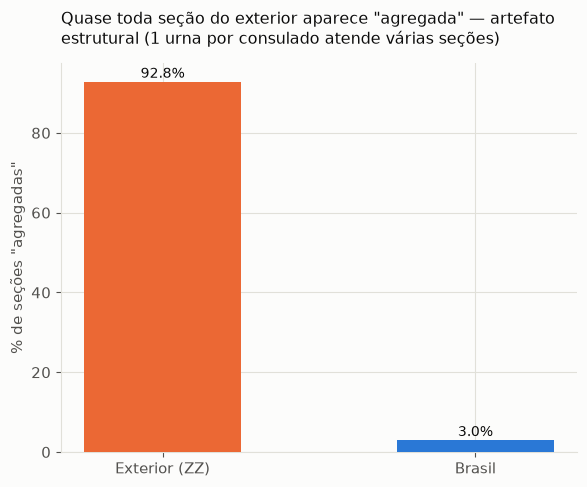

In [25]:
pct_zz = 100*secao_full.loc[secao_full.is_zz, 'is_agregada'].mean()
pct_br = 100*secao_full.loc[~secao_full.is_zz, 'is_agregada'].mean()
fig, ax = plt.subplots(figsize=(6, 5))
ax.bar(["Exterior (ZZ)", "Brasil"], [pct_zz, pct_br], color=[FLAVIO, LULA], width=0.5, zorder=3)
for i, v in enumerate([pct_zz, pct_br]):
    ax.text(i, v+1, f"{v:.1f}%", ha="center", fontsize=10)
ax.set_ylabel('% de seções "agregadas"')
ax.set_title('Quase toda seção do exterior aparece "agregada" — artefato\nestrutural (1 urna por consulado atende várias seções)', fontsize=11.5, loc="left", pad=14)
fig.tight_layout()
plt.show()

### Exterior: comparação 1º × 2º turno

Com o BU Web do 1º turno agora disponível, dá pra ver o quadro completo do voto no exterior entre os dois turnos — o padrão é de **polarização** (cada região intensifica a direção que já tinha), não de troca de lado.

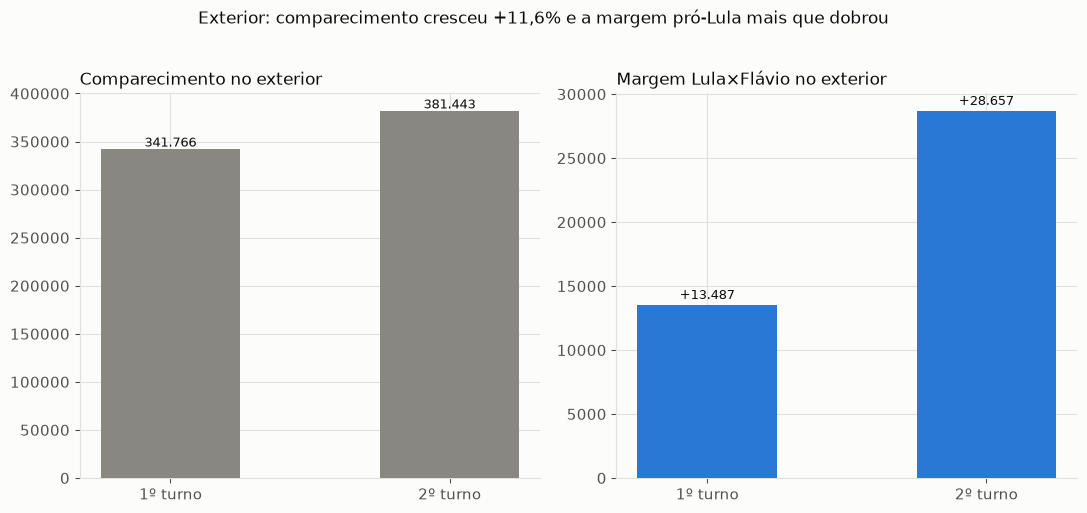

In [26]:
ext_comp = con.sql(f"""
    SELECT NR_TURNO, SUM(QT_VOTOS) AS total_votos
    FROM read_csv('{CSV_PATH}', delim=';', encoding='latin1', header=True)
    WHERE SG_UF='ZZ' GROUP BY NR_TURNO ORDER BY NR_TURNO
""").df()

ext_cand = con.sql(f"""
    SELECT NR_TURNO, NM_VOTAVEL, SUM(QT_VOTOS) AS votos
    FROM read_csv('{CSV_PATH}', delim=';', encoding='latin1', header=True)
    WHERE SG_UF='ZZ' AND NM_VOTAVEL IN ('LUIZ INÁCIO LULA DA SILVA','FLAVIO NANTES BOLSONARO')
    GROUP BY NR_TURNO, NM_VOTAVEL ORDER BY NR_TURNO, votos DESC
""").df()

def ext_votos(turno, cand):
    return ext_cand[(ext_cand.NR_TURNO==turno) & (ext_cand.NM_VOTAVEL.str.contains(cand))]['votos'].values[0]

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
ax = axes[0]
comp = ext_comp.set_index('NR_TURNO')['total_votos']
ax.bar(['1º turno', '2º turno'], [comp[1], comp[2]], color=MUTED, width=0.5, zorder=3)
for i, v in enumerate([comp[1], comp[2]]):
    ax.text(i, v+3000, f'{v:,.0f}'.replace(',','.'), ha='center', fontsize=9.5)
ax.set_title('Comparecimento no exterior', fontsize=12, loc='left')

ax = axes[1]
margem_1t = ext_votos(1,'LULA') - ext_votos(1,'BOLSONARO')
margem_2t = ext_votos(2,'LULA') - ext_votos(2,'BOLSONARO')
ax.bar(['1º turno', '2º turno'], [margem_1t, margem_2t], color=[LULA, LULA], width=0.5, zorder=3)
for i, v in enumerate([margem_1t, margem_2t]):
    ax.text(i, v+500, f'+{v:,.0f}'.replace(',','.'), ha='center', fontsize=9.5)
ax.set_title('Margem Lula×Flávio no exterior', fontsize=12, loc='left')
fig.suptitle('Exterior: comparecimento cresceu +11,6% e a margem pró-Lula mais que dobrou', fontsize=12.5, y=1.02)
fig.tight_layout()
plt.show()

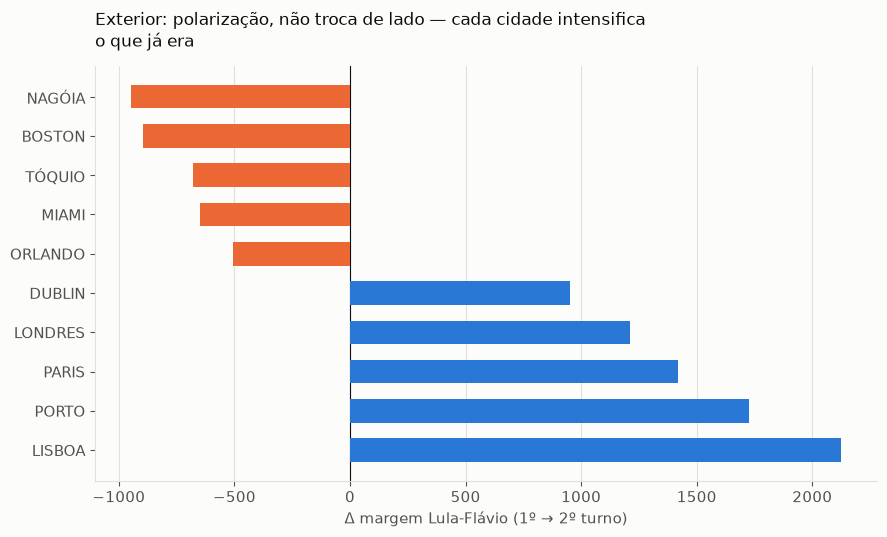

In [27]:
ext_city = con.sql(f"""
    SELECT NM_MUNICIPIO, NR_TURNO, NM_VOTAVEL, SUM(QT_VOTOS) AS votos
    FROM read_csv('{CSV_PATH}', delim=';', encoding='latin1', header=True)
    WHERE SG_UF='ZZ' AND NM_VOTAVEL IN ('LUIZ INÁCIO LULA DA SILVA','FLAVIO NANTES BOLSONARO')
    GROUP BY NM_MUNICIPIO, NR_TURNO, NM_VOTAVEL
""").df()

piv = ext_city.pivot_table(index='NM_MUNICIPIO', columns=['NR_TURNO','NM_VOTAVEL'], values='votos', fill_value=0)
piv.columns = ['_'.join(map(str,c)) for c in piv.columns]
piv['margem_1t'] = piv['1_LUIZ INÁCIO LULA DA SILVA'] - piv['1_FLAVIO NANTES BOLSONARO']
piv['margem_2t'] = piv['2_LUIZ INÁCIO LULA DA SILVA'] - piv['2_FLAVIO NANTES BOLSONARO']
piv['delta_margem'] = piv['margem_2t'] - piv['margem_1t']
piv['total_2t'] = piv['2_LUIZ INÁCIO LULA DA SILVA'] + piv['2_FLAVIO NANTES BOLSONARO']
top = piv[piv['total_2t']>=200].sort_values('delta_margem', ascending=False)

cidades = list(top.head(5).index) + list(top.tail(5).index)
deltas = list(top.head(5)['delta_margem']) + list(top.tail(5)['delta_margem'])
colors_c = [LULA]*5 + [FLAVIO]*5

fig, ax = plt.subplots(figsize=(9, 5.5))
y = np.arange(len(cidades))
ax.barh(y, deltas, color=colors_c, height=0.6, zorder=3)
ax.set_yticks(y, cidades)
ax.axvline(0, color=INK, linewidth=0.8)
ax.set_xlabel('Δ margem Lula-Flávio (1º → 2º turno)')
ax.set_title('Exterior: polarização, não troca de lado — cada cidade intensifica\no que já era', fontsize=12.5, loc='left', pad=14)
ax.grid(axis='y', visible=False)
fig.tight_layout()
plt.show()

### De onde vem o aumento de margem no exterior

Mesma decomposição de pool da seção nacional (Salvador/Nordeste), agora só para o exterior: o comparecimento cresceu bem mais que a média nacional (+11,6% vs +2,4%), mas isso sozinho não explica tudo — os votos de candidatos eliminados no 1º turno também formam um pool relevante.

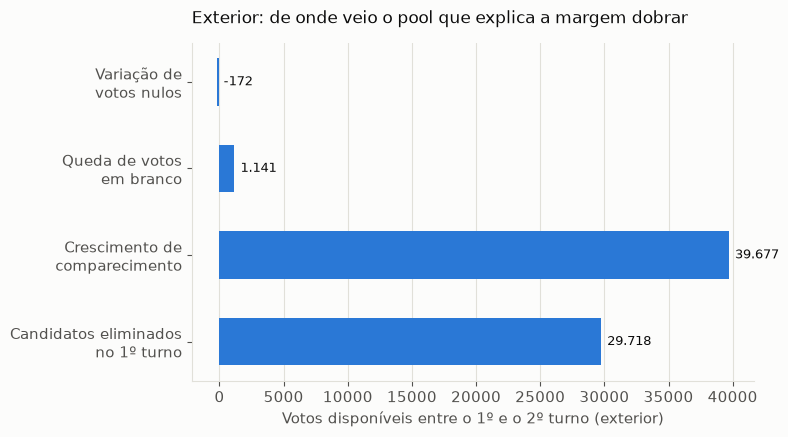

In [28]:
tot_1t_zz = con.sql(f"""
    SELECT NM_VOTAVEL, SUM(QT_VOTOS) AS votos
    FROM read_csv('{CSV_PATH}', delim=';', encoding='latin1', header=True)
    WHERE SG_UF='ZZ' AND NR_TURNO = 1 GROUP BY NM_VOTAVEL
""").df()

lula_1t_zz = tot_1t_zz[tot_1t_zz.NM_VOTAVEL.str.contains("LULA")]['votos'].sum()
flavio_1t_zz = tot_1t_zz[tot_1t_zz.NM_VOTAVEL.str.contains("BOLSONARO")]['votos'].sum()
nulo_1t_zz = tot_1t_zz[tot_1t_zz.NM_VOTAVEL == "VOTO NULO"]['votos'].sum()
branco_1t_zz = tot_1t_zz[tot_1t_zz.NM_VOTAVEL == "VOTO BRANCO"]['votos'].sum()
outros_1t_zz = tot_1t_zz['votos'].sum() - lula_1t_zz - flavio_1t_zz - nulo_1t_zz - branco_1t_zz

nulo_2t_zz = ext_comp.set_index('NR_TURNO')['total_votos'][2] - ext_votos(2,"LULA") - ext_votos(2,"BOLSONARO")
# nulo e branco 2T exterior, direto da fonte
tot_2t_zz = con.sql(f"""
    SELECT NM_VOTAVEL, SUM(QT_VOTOS) AS votos
    FROM read_csv('{CSV_PATH}', delim=';', encoding='latin1', header=True)
    WHERE SG_UF='ZZ' AND NR_TURNO = 2 GROUP BY NM_VOTAVEL
""").df()
nulo_2t_zz = tot_2t_zz[tot_2t_zz.NM_VOTAVEL == "VOTO NULO"]['votos'].sum()
branco_2t_zz = tot_2t_zz[tot_2t_zz.NM_VOTAVEL == "VOTO BRANCO"]['votos'].sum()

growth_zz = (ext_votos(2,"LULA") + ext_votos(2,"BOLSONARO") + nulo_2t_zz + branco_2t_zz) - \
            (lula_1t_zz + flavio_1t_zz + nulo_1t_zz + branco_1t_zz + outros_1t_zz)

pool_zz = {
    "Candidatos eliminados\nno 1º turno": outros_1t_zz,
    "Crescimento de\ncomparecimento": growth_zz,
    "Queda de votos\nem branco": branco_1t_zz - branco_2t_zz,
    "Variação de\nvotos nulos": nulo_1t_zz - nulo_2t_zz,
}

fig, ax = plt.subplots(figsize=(8, 4.5))
labels_zz = list(pool_zz.keys())
vals_zz = list(pool_zz.values())
ax.barh(labels_zz, vals_zz, color=LULA, height=0.55, zorder=3)
for i, v in enumerate(vals_zz):
    ax.text(v + 500, i, f"{v:,.0f}".replace(",", "."), va="center", fontsize=9.5)
ax.set_xlabel("Votos disponíveis entre o 1º e o 2º turno (exterior)")
ax.set_title("Exterior: de onde veio o pool que explica a margem dobrar", fontsize=12.5, loc="left", pad=14)
ax.grid(axis="y", visible=False)
fig.tight_layout()
plt.show()

### Salvador e Nordeste: o que de fato explica a virada de margem entre turnos

Salvador foi o maior swing absoluto de margem entre turnos do país — mas isso **não generaliza** pra "o Nordeste decidiu via comparecimento": o Nordeste nem teve o maior crescimento de comparecimento do país, e dentro dele mesmo a maior parte do ganho de Lula vem de transferência de voto de candidatos eliminados no 1º turno, não de eleitor novo.

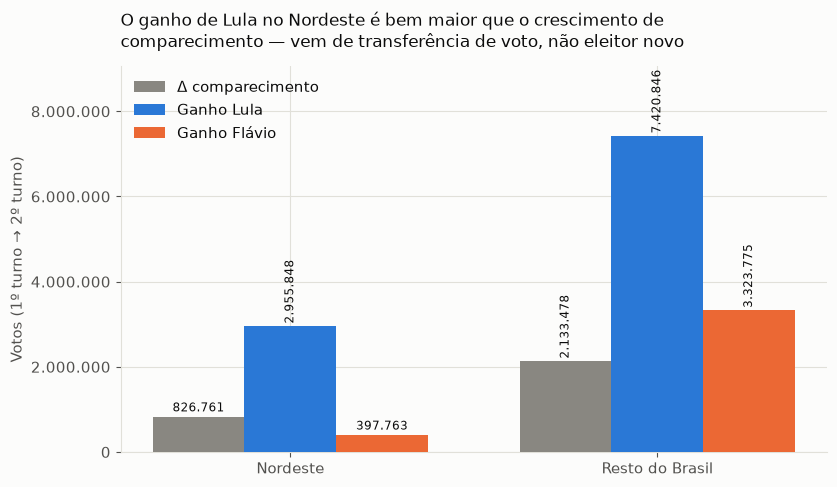

In [29]:
NE = ('AL', 'BA', 'CE', 'MA', 'PB', 'PE', 'PI', 'RN', 'SE')
ne_list = ','.join(f"'{u}'" for u in NE)

comp_regiao = con.sql(f"""
    SELECT CASE WHEN SG_UF IN ({ne_list}) THEN 'Nordeste' ELSE 'Resto do Brasil' END AS regiao,
        NR_TURNO, SUM(QT_VOTOS) AS total_votos
    FROM read_csv('{CSV_PATH}', delim=';', encoding='latin1', header=True)
    GROUP BY 1, 2 ORDER BY 1, 2
""").df()

votos_regiao = con.sql(f"""
    SELECT CASE WHEN SG_UF IN ({ne_list}) THEN 'Nordeste' ELSE 'Resto do Brasil' END AS regiao,
        NR_TURNO, NM_VOTAVEL, SUM(QT_VOTOS) AS votos
    FROM read_csv('{CSV_PATH}', delim=';', encoding='latin1', header=True)
    WHERE NM_VOTAVEL IN ('LUIZ INÁCIO LULA DA SILVA', 'FLAVIO NANTES BOLSONARO')
    GROUP BY 1, 2, 3 ORDER BY 1, 2, 3
""").df()

def delta_comp(regiao):
    s = comp_regiao[comp_regiao.regiao == regiao].set_index('NR_TURNO')['total_votos']
    return s[2] - s[1]

def ganho(regiao, candidato):
    s = votos_regiao[(votos_regiao.regiao == regiao) & (votos_regiao.NM_VOTAVEL.str.contains(candidato))].set_index('NR_TURNO')['votos']
    return s[2] - s[1]

fig, ax = plt.subplots(figsize=(8.5, 5))
x = np.arange(2); width = 0.25
regioes = ["Nordeste", "Resto do Brasil"]
comp_vals = [delta_comp(r) for r in regioes]
lula_vals = [ganho(r, "LULA") for r in regioes]
flavio_vals = [ganho(r, "BOLSONARO") for r in regioes]
ax.bar(x-width, comp_vals, width, color=MUTED, label="Δ comparecimento", zorder=3)
ax.bar(x, lula_vals, width, color=LULA, label="Ganho Lula", zorder=3)
ax.bar(x+width, flavio_vals, width, color=FLAVIO, label="Ganho Flávio", zorder=3)
ax.set_xticks(x, regioes)
ax.set_ylabel("Votos (1º turno → 2º turno)")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(fmt_milhar))
ax.set_title("O ganho de Lula no Nordeste é bem maior que o crescimento de\ncomparecimento — vem de transferência de voto, não eleitor novo", fontsize=12, loc="left", pad=14)
for xi, vals in [(x-width, comp_vals), (x, lula_vals), (x+width, flavio_vals)]:
    for xii, v in zip(xi, vals):
        ax.text(xii, v + 60000, f"{v:,.0f}".replace(",", "."), ha="center", fontsize=8.5, rotation=90 if v > 1000000 else 0, va="bottom")
ax.set_ylim(0, max(lula_vals) * 1.22)
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

### O swing do Nordeste é maior que os três mecanismos testados somados

Mas isso não é comparável a eles no sentido que importa: prorrogação/agregação/biometria testam um **incidente operacional**; o swing do Nordeste é consolidação política normal de 2º turno numa região que já era maciçamente pró-Lula — não um evento do dia da eleição.

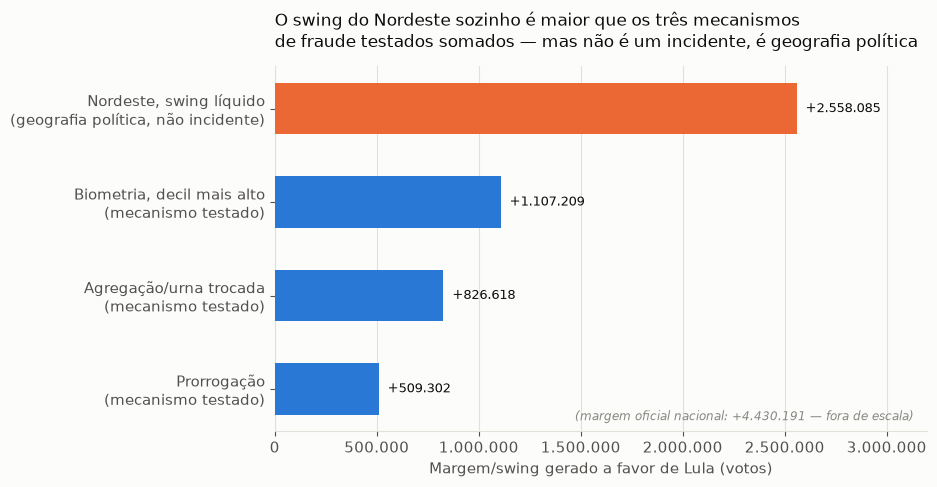

In [30]:
swing_ne = lula_vals[0] - flavio_vals[0]
swing_resto = lula_vals[1] - flavio_vals[1]

margem_prorr = secao_full[secao_full.is_prorrogada]['lula'].sum() - secao_full[secao_full.is_prorrogada]['flavio'].sum()
g_agreg = secao_full[secao_full.is_agregada & ~secao_full.is_zz]
margem_agreg = g_agreg['lula'].sum() - g_agreg['flavio'].sum()
margem_biom = decil10_biom['lula'].sum() - decil10_biom['flavio'].sum()

comparacao = {
    "Prorrogação\n(mecanismo testado)": margem_prorr,
    "Agregação/urna trocada\n(mecanismo testado)": margem_agreg,
    "Biometria, decil mais alto\n(mecanismo testado)": margem_biom,
    "Nordeste, swing líquido\n(geografia política, não incidente)": swing_ne,
}

fig, ax = plt.subplots(figsize=(9.5, 5))
labels_c = list(comparacao.keys())
vals_c = list(comparacao.values())
colors_c = [LULA, LULA, LULA, FLAVIO]
y = np.arange(len(labels_c))
ax.barh(y, vals_c, color=colors_c, height=0.55, zorder=3)
ax.set_yticks(y, labels_c)
ax.set_xlabel("Margem/swing gerado a favor de Lula (votos)")
ax.set_title("O swing do Nordeste sozinho é maior que os três mecanismos\nde fraude testados somados — mas não é um incidente, é geografia política", fontsize=12, loc="left", pad=14)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(fmt_milhar))
for yi, v in zip(y, vals_c):
    ax.text(v + MARGEM_NAC*0.01, yi, f"+{v:,.0f}".replace(",", "."), va="center", fontsize=9.5, color=INK)
ax.set_xlim(0, max(vals_c)*1.25)
ax.text(0.98, 0.03, f"(margem oficial nacional: +{MARGEM_NAC:,.0f} — fora de escala)".replace(",", "."), transform=ax.transAxes, ha="right", fontsize=8.5, color=MUTED, style="italic")
ax.grid(axis="y", visible=False)
fig.tight_layout()
plt.show()

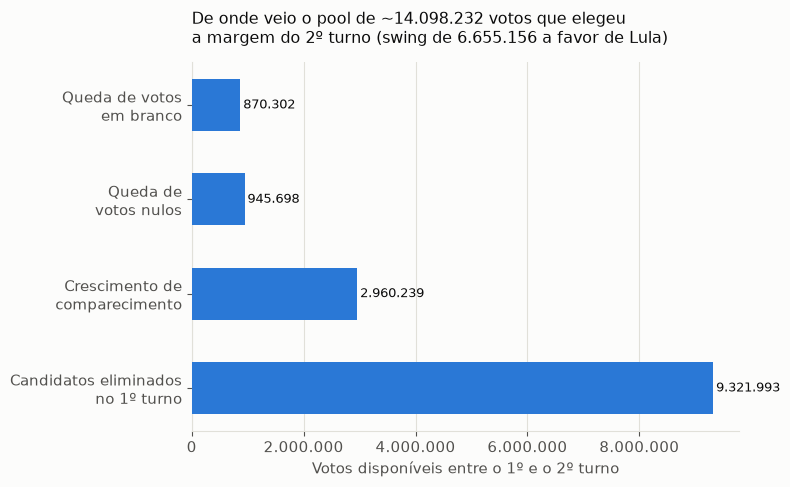

In [31]:
tot_1t = con.sql(f"""
    SELECT NM_VOTAVEL, SUM(QT_VOTOS) AS votos
    FROM read_csv('{CSV_PATH}', delim=';', encoding='latin1', header=True)
    WHERE NR_TURNO = 1 GROUP BY NM_VOTAVEL
""").df()

lula_1t = tot_1t[tot_1t.NM_VOTAVEL.str.contains("LULA")]['votos'].sum()
flavio_1t = tot_1t[tot_1t.NM_VOTAVEL.str.contains("BOLSONARO")]['votos'].sum()
nulo_1t = tot_1t[tot_1t.NM_VOTAVEL == "VOTO NULO"]['votos'].sum()
branco_1t = tot_1t[tot_1t.NM_VOTAVEL == "VOTO BRANCO"]['votos'].sum()
outros_1t = tot_1t['votos'].sum() - lula_1t - flavio_1t - nulo_1t - branco_1t

nulo_2t = secao_full['nulo'].sum()
branco_2t = secao_full['branco'].sum()
growth = (LULA_NAC + FLAVIO_NAC + nulo_2t + branco_2t) - (lula_1t + flavio_1t + nulo_1t + branco_1t + outros_1t)

pool = {
    "Candidatos eliminados\nno 1º turno": outros_1t,
    "Crescimento de\ncomparecimento": growth,
    "Queda de\nvotos nulos": nulo_1t - nulo_2t,
    "Queda de votos\nem branco": branco_1t - branco_2t,
}

fig, ax = plt.subplots(figsize=(8, 5))
labels = list(pool.keys())
vals = list(pool.values())
ax.barh(labels, vals, color=LULA, height=0.55, zorder=3)
for i, v in enumerate(vals):
    ax.text(v + 50000, i, f"{v:,.0f}".replace(",", "."), va="center", fontsize=9.5)
ax.set_xlabel("Votos disponíveis entre o 1º e o 2º turno")
ax.set_title(f"De onde veio o pool de ~{sum(vals):,.0f} votos que elegeu\na margem do 2º turno (swing de {MARGEM_NAC - (lula_1t-flavio_1t):,.0f} a favor de Lula)".replace(",", "."), fontsize=11.5, loc="left", pad=14)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(fmt_milhar))
ax.grid(axis="y", visible=False)
fig.tight_layout()
plt.show()

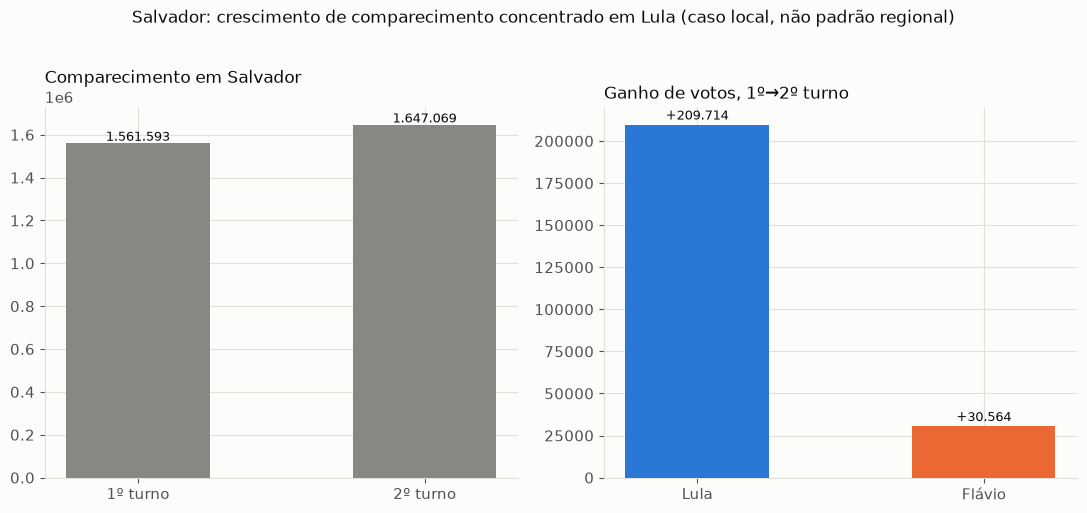

In [32]:
salvador = con.sql(f"""
    SELECT NR_TURNO, NM_VOTAVEL, SUM(QT_VOTOS) AS votos
    FROM read_csv('{CSV_PATH}', delim=';', encoding='latin1', header=True)
    WHERE SG_UF='BA' AND NM_MUNICIPIO='SALVADOR' AND NM_VOTAVEL IN ('LUIZ INÁCIO LULA DA SILVA','FLAVIO NANTES BOLSONARO')
    GROUP BY NR_TURNO, NM_VOTAVEL
""").df()
salvador_comp = con.sql(f"""
    SELECT NR_TURNO, SUM(QT_VOTOS) AS total
    FROM read_csv('{CSV_PATH}', delim=';', encoding='latin1', header=True)
    WHERE SG_UF='BA' AND NM_MUNICIPIO='SALVADOR' GROUP BY NR_TURNO
""").df().set_index('NR_TURNO')['total']

def sv(turno, cand):
    return salvador[(salvador.NR_TURNO==turno) & (salvador.NM_VOTAVEL.str.contains(cand))]['votos'].values[0]

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
ax = axes[0]
ax.bar(["1º turno", "2º turno"], [salvador_comp[1], salvador_comp[2]], color=MUTED, width=0.5, zorder=3)
ax.set_title("Comparecimento em Salvador", fontsize=12, loc="left")
for i, v in enumerate([salvador_comp[1], salvador_comp[2]]):
    ax.text(i, v+10000, f"{v:,.0f}".replace(",", "."), ha="center", fontsize=9.5)
ax = axes[1]
ganho_lula_sv = sv(2,"LULA") - sv(1,"LULA")
ganho_flavio_sv = sv(2,"BOLSONARO") - sv(1,"BOLSONARO")
ax.bar(["Lula", "Flávio"], [ganho_lula_sv, ganho_flavio_sv], color=[LULA, FLAVIO], width=0.5, zorder=3)
ax.set_title("Ganho de votos, 1º→2º turno", fontsize=12, loc="left")
for i, v in enumerate([ganho_lula_sv, ganho_flavio_sv]):
    ax.text(i, v+3000, f"+{v:,.0f}".replace(",", "."), ha="center", fontsize=9.5)
fig.suptitle("Salvador: crescimento de comparecimento concentrado em Lula (caso local, não padrão regional)", fontsize=12.5, y=1.02)
fig.tight_layout()
plt.show()

### Branco/nulo: o teste com resultado mais nulo da análise

Mesmo método da biometria (decis de taxa por seção), mas sem o mesmo padrão direcional — e sem explicar as "ilhas lulistas" em território bolsonarista, do mesmo jeito que biometria não explicou.

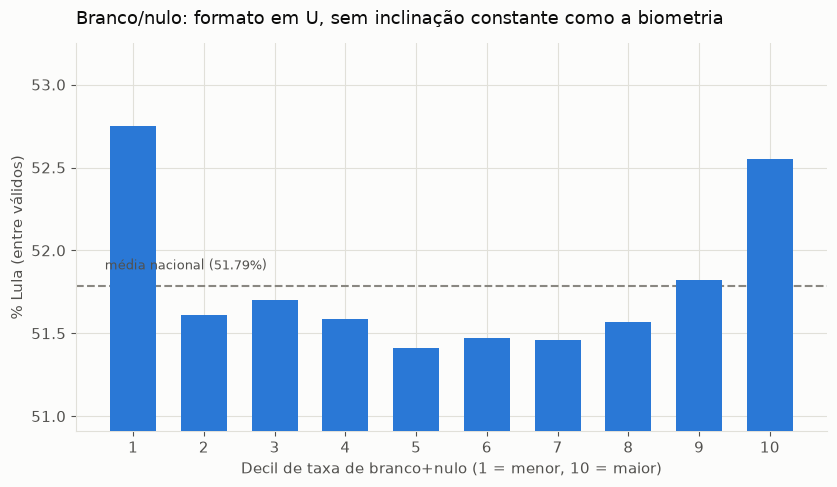

In [33]:
con.execute("""
CREATE OR REPLACE VIEW sub_decil_bn AS
SELECT *, NTILE(10) OVER (ORDER BY taxa_bn) AS decil_bn
FROM secao_full WHERE NOT is_zz AND comparecimento > 0 AND taxa_bn IS NOT NULL
""")
dec_bn = con.sql("""
    SELECT decil_bn, SUM(lula) lula, SUM(flavio) flavio
    FROM sub_decil_bn GROUP BY decil_bn ORDER BY decil_bn
""").df()
dec_bn['pct_lula'] = 100*dec_bn['lula']/(dec_bn['lula']+dec_bn['flavio'])
pct_nac_validos = 100*LULA_NAC/(LULA_NAC+FLAVIO_NAC)

fig, ax = plt.subplots(figsize=(8.5, 5))
ax.bar(dec_bn['decil_bn'], dec_bn['pct_lula'], color=LULA, width=0.65, zorder=3)
ax.axhline(pct_nac_validos, color=MUTED, linestyle="--", linewidth=1.5, zorder=2)
ax.text(0.6, pct_nac_validos+0.1, f"média nacional ({pct_nac_validos:.2f}%)", color=TEXT, fontsize=9)
ax.set_xticks(dec_bn['decil_bn'])
ax.set_xlabel("Decil de taxa de branco+nulo (1 = menor, 10 = maior)")
ax.set_ylabel("% Lula (entre válidos)")
ax.set_title("Branco/nulo: formato em U, sem inclinação constante como a biometria", fontsize=13, loc="left", pad=14)
ax.set_ylim(dec_bn["pct_lula"].min()-0.5, dec_bn["pct_lula"].max()+0.5)
fig.tight_layout()
plt.show()

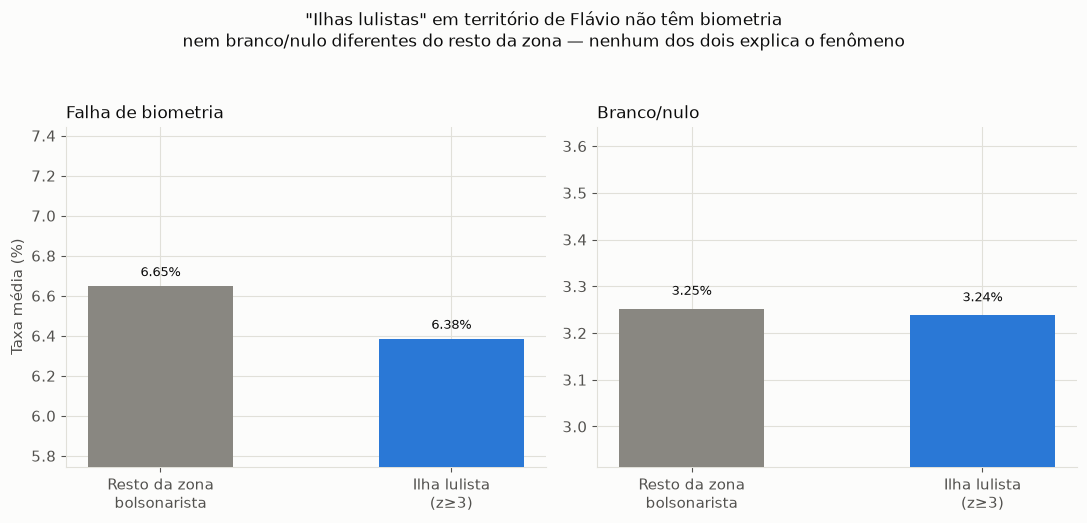

In [34]:
con.execute("""
CREATE OR REPLACE VIEW secao_pct AS
SELECT *, lula+flavio AS validos, 100.0*lula/(lula+flavio) AS pct_lula
FROM secao_full WHERE lula+flavio >= 20
""")
con.execute("""
CREATE OR REPLACE VIEW zona_stats AS
SELECT SG_UF, NM_MUNICIPIO, NR_ZONA, AVG(pct_lula) AS media_zona, STDDEV(pct_lula) AS std_zona, COUNT(*) AS n_secoes
FROM secao_pct GROUP BY SG_UF, NM_MUNICIPIO, NR_ZONA HAVING COUNT(*) >= 15
""")
com_z = con.sql("""
    SELECT sp.*, zs.media_zona, zs.std_zona, (sp.pct_lula - zs.media_zona)/zs.std_zona AS z
    FROM secao_pct sp JOIN zona_stats zs USING (SG_UF, NM_MUNICIPIO, NR_ZONA)
    WHERE zs.std_zona > 0 AND zs.media_zona < 50
""").df()

ilha = com_z[com_z.z >= 3]
resto = com_z[com_z.z < 3]

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
ax = axes[0]
vals_biom = [resto.taxa_biom_falha.mean(), ilha.taxa_biom_falha.mean()]
ax.bar(["Resto da zona\nbolsonarista", "Ilha lulista\n(z≥3)"], vals_biom, color=[MUTED, LULA], width=0.5, zorder=3)
for i, v in enumerate(vals_biom):
    ax.text(i, v+0.05, f"{v:.2f}%", ha="center", fontsize=9.5)
ax.set_title("Falha de biometria", fontsize=12, loc="left")
ax.set_ylabel("Taxa média (%)")
ax.set_ylim(min(vals_biom)*0.9, max(vals_biom)*1.12)
ax = axes[1]
vals_bn = [resto.taxa_bn.mean(), ilha.taxa_bn.mean()]
ax.bar(["Resto da zona\nbolsonarista", "Ilha lulista\n(z≥3)"], vals_bn, color=[MUTED, LULA], width=0.5, zorder=3)
for i, v in enumerate(vals_bn):
    ax.text(i, v+0.03, f"{v:.2f}%", ha="center", fontsize=9.5)
ax.set_title("Branco/nulo", fontsize=12, loc="left")
ax.set_ylim(min(vals_bn)*0.9, max(vals_bn)*1.12)
fig.suptitle('"Ilhas lulistas" em território de Flávio não têm biometria\nnem branco/nulo diferentes do resto da zona — nenhum dos dois explica o fenômeno', fontsize=12, y=1.04)
fig.tight_layout()
plt.show()

### Seções com resultado numericamente idêntico

Teste de forense eleitoral clássico: existem seções com a contagem exata de votos (Lula, Flávio, Branco, Nulo) repetida em outra seção? Cópia de boletim produziria concentração geográfica e nas seções maiores — os testes abaixo checam se é isso que acontece.

In [35]:
con.execute("""
CREATE OR REPLACE VIEW duplicatas_grupo AS
SELECT lula, flavio, branco, nulo, comparecimento, COUNT(*) AS n_secoes
FROM secao_full
WHERE comparecimento > 0
GROUP BY lula, flavio, branco, nulo, comparecimento
HAVING COUNT(*) >= 2
""")

secoes_dup = con.sql("""
SELECT s.SG_UF, s.NM_MUNICIPIO, s.NR_ZONA, s.NR_SECAO, s.lula, s.flavio, s.branco, s.nulo, s.comparecimento
FROM secao_full s
JOIN duplicatas_grupo g USING (lula, flavio, branco, nulo, comparecimento)
WHERE s.comparecimento > 0
""").df()

secoes_ativas = int((secao_full.comparecimento > 0).sum())
print(f"Seções ativas (território nacional, incl. exterior): {secoes_ativas:,}".replace(",", "."))
print(f"Seções com tupla duplicada: {len(secoes_dup):,} ({100*len(secoes_dup)/secoes_ativas:.2f}%)".replace(",", "."))

margem_dup = secoes_dup['lula'].sum() - secoes_dup['flavio'].sum()
margem_excl_dup = (LULA_NAC - secoes_dup['lula'].sum()) - (FLAVIO_NAC - secoes_dup['flavio'].sum())
pct_lula_dup = 100*secoes_dup['lula'].sum()/(secoes_dup['lula'].sum()+secoes_dup['flavio'].sum())
print(f"Margem dentro das duplicadas: {margem_dup:+,.0f} ({pct_lula_dup:.2f}% Lula)".replace(",", "."))
print(f"Margem nacional excluindo as duplicadas: {margem_excl_dup:+,.0f}".replace(",", "."))

geo = con.sql("""
WITH g AS (
    SELECT lula, flavio, branco, nulo, comparecimento,
           COUNT(DISTINCT SG_UF) AS n_ufs,
           COUNT(DISTINCT (SG_UF || NM_MUNICIPIO || NR_ZONA::VARCHAR)) AS n_zonas,
           COUNT(*) AS n_secoes
    FROM secao_full
    WHERE comparecimento > 0
    GROUP BY lula, flavio, branco, nulo, comparecimento
    HAVING COUNT(*) >= 2
)
SELECT
    SUM(CASE WHEN n_zonas=1 THEN n_secoes ELSE 0 END) AS mesma_zona,
    SUM(CASE WHEN n_ufs=1 AND n_zonas>1 THEN n_secoes ELSE 0 END) AS mesma_uf_outra_zona,
    SUM(CASE WHEN n_ufs>1 THEN n_secoes ELSE 0 END) AS ufs_diferentes,
    SUM(n_secoes) AS total
FROM g
""").df()
print("\nDispersão geográfica dos grupos duplicados (quanto mais em UFs diferentes, mais parece coincidência, não cópia local):")
print(geo.to_string(index=False))

por_uf_dup = secoes_dup.groupby('SG_UF').size().rename('secoes_duplicadas')
total_por_uf = secao_full[secao_full.comparecimento > 0].groupby('SG_UF').size().rename('total_secoes')
uf_dup = pd.concat([total_por_uf, por_uf_dup], axis=1).fillna(0)
uf_dup['pct'] = 100*uf_dup['secoes_duplicadas']/uf_dup['total_secoes']
print("\nTop 10 UFs por taxa de duplicação:")
uf_dup.sort_values('pct', ascending=False).head(10)

Seções ativas (território nacional. incl. exterior): 499.205
Seções com tupla duplicada: 117.752 (23.59%)
Margem dentro das duplicadas: -14.141 (49.98% Lula)
Margem nacional excluindo as duplicadas: +4.444.332



Dispersão geográfica dos grupos duplicados (quanto mais em UFs diferentes, mais parece coincidência, não cópia local):
 mesma_zona  mesma_uf_outra_zona  ufs_diferentes    total
      286.0              14340.0        103126.0 117752.0

Top 10 UFs por taxa de duplicação:


,total_secoes,secoes_duplicadas,pct
SG_UF,,,
DF,6969,2278,32.687617
MS,7106,2255,31.733746
GO,15686,4835,30.823664
AP,1914,557,29.101358
PR,27142,7775,28.645641
RJ,37675,10423,27.665561
PA,20827,5492,26.369616
MG,52062,13519,25.967116
RS,27547,6788,24.641522


In [36]:
df_secoes = secao_full[(secao_full.SG_UF=='DF') & (secao_full.comparecimento > 0)]
df_geral_margem = df_secoes['lula'].sum() - df_secoes['flavio'].sum()
pct_lula_df = 100*df_secoes['lula'].sum()/(df_secoes['lula'].sum()+df_secoes['flavio'].sum())
print(f"DF geral: Lula {df_secoes['lula'].sum():,.0f} x Flávio {df_secoes['flavio'].sum():,.0f} (margem {df_geral_margem:+,.0f}, {pct_lula_df:.2f}% Lula)".replace(",", "."))

df_dup_grupos = df_secoes.groupby(['lula','flavio','branco','nulo','comparecimento']).size()
df_dup_grupos = df_dup_grupos[df_dup_grupos >= 2]
df_secoes_internas = df_secoes.set_index(['lula','flavio','branco','nulo','comparecimento']).loc[df_dup_grupos.index].reset_index()

print(f"\nSeções do DF que duplicam com OUTRA seção do próprio DF: {len(df_secoes_internas)} ({len(df_dup_grupos)} grupos)")
margem_df_int = df_secoes_internas['lula'].sum() - df_secoes_internas['flavio'].sum()
pct_lula_df_int = 100*df_secoes_internas['lula'].sum()/(df_secoes_internas['lula'].sum()+df_secoes_internas['flavio'].sum())
print(f"Margem dentro dessas {len(df_secoes_internas)} seções: {margem_df_int:+,.0f} ({pct_lula_df_int:.2f}% Lula, vs {pct_lula_df:.2f}% do DF geral — sem distorção)".replace(",", "."))

DF geral: Lula 825.224 x Flávio 979.542 (margem -154.318. 45.72% Lula)

Seções do DF que duplicam com OUTRA seção do próprio DF: 125 (62 grupos)
Margem dentro dessas 125 seções: -2.810 (45.61% Lula. vs 45.72% do DF geral — sem distorção)


### Seções com zero votos em um dos candidatos — e o que diz o 1º turno

Existe seção ativa (comparecimento > 0) onde um dos dois candidatos recebeu zero votos? E, se existe, o padrão já aparecia no 1º turno — antes de qualquer dinâmica de consolidação do 2º turno?

In [37]:
secoes_ativas_nac = secao_full[secao_full.comparecimento > 0]
zero_lula = secoes_ativas_nac[secoes_ativas_nac.lula == 0]
zero_flavio = secoes_ativas_nac[secoes_ativas_nac.flavio == 0]

print(f"Seções com Lula=0: {len(zero_lula)} ({100*len(zero_lula)/len(secoes_ativas_nac):.3f}%)")
print(f"Seções com Flávio=0: {len(zero_flavio)} ({100*len(zero_flavio)/len(secoes_ativas_nac):.3f}%)")

print("\nSeções com Lula=0:")
print(zero_lula[['SG_UF','NM_MUNICIPIO','NR_ZONA','NR_SECAO','comparecimento','flavio']].sort_values('comparecimento', ascending=False).to_string(index=False))

print("\nTop 10 seções com Flávio=0 por comparecimento:")
print(zero_flavio[['SG_UF','NM_MUNICIPIO','NR_ZONA','NR_SECAO','comparecimento','lula']].sort_values('comparecimento', ascending=False).head(10).to_string(index=False))

print("\nFlávio=0 por UF (top 5):")
print(zero_flavio['SG_UF'].value_counts().head(5))

Seções com Lula=0: 4 (0.001%)
Seções com Flávio=0: 106 (0.021%)

Seções com Lula=0:
SG_UF    NM_MUNICIPIO  NR_ZONA  NR_SECAO  comparecimento  flavio
   RS ARROIO DO PADRE       34       433             118   116.0
   RS   CÂNDIDO GODÓI      166        81              85    82.0
   PA    JACAREACANGA      102        44              50    50.0
   PA          CHAVES       17        41              49    48.0

Top 10 seções com Flávio=0 por comparecimento:
SG_UF          NM_MUNICIPIO  NR_ZONA  NR_SECAO  comparecimento  lula
   AM             TABATINGA       36        61             365 354.0
   AM             TABATINGA       36        96             347 338.0
   AM                 MAUÉS        5       176             337 333.0
   AM      ATALAIA DO NORTE       42        29             335 325.0
   AM  SANTO ANTÔNIO DO IÇÁ       47         9             330 329.0
   PR            ORTIGUEIRA      167        96             317 314.0
   AM  SANTO ANTÔNIO DO IÇÁ       47        87             3

In [38]:
# ATENÇÃO: esta célula varre o BU Web do 1º turno (~35GB, todos os cargos) — pode levar alguns minutos.
BU_PATH_1T = "../data/bu_web_1t/*.csv"

zeradas_2t = pd.concat([
    zero_lula.assign(tipo='lula_zero'),
    zero_flavio.assign(tipo='flavio_zero'),
])[['SG_UF','NM_MUNICIPIO','NR_ZONA','NR_SECAO','tipo','comparecimento','lula','flavio']]

secao_1t = con.sql(f"""
    SELECT
        SG_UF, NM_MUNICIPIO, NR_ZONA, NR_SECAO,
        MAX(QT_COMPARECIMENTO) AS comparecimento_1t,
        SUM(CASE WHEN NM_VOTAVEL='LULA' THEN QT_VOTOS ELSE 0 END) AS lula_1t,
        SUM(CASE WHEN NM_VOTAVEL='FLAVIO BOLSONARO' THEN QT_VOTOS ELSE 0 END) AS flavio_1t
    FROM read_csv('{BU_PATH_1T}', delim=';', encoding='latin1', union_by_name=True, header=True)
    WHERE DS_CARGO_PERGUNTA='Presidente'
    GROUP BY SG_UF, NM_MUNICIPIO, NR_ZONA, NR_SECAO
""").df()

cruzado = zeradas_2t.merge(secao_1t, on=['SG_UF','NM_MUNICIPIO','NR_ZONA','NR_SECAO'], how='left')
lula_zero_1t = cruzado[cruzado.tipo=='lula_zero']
flavio_zero_1t = cruzado[cruzado.tipo=='flavio_zero']

print(f"Lula=0 no 2T que também eram Lula=0 no 1T: {(lula_zero_1t.lula_1t==0).sum()} de {len(lula_zero_1t)}")
print(f"Flávio=0 no 2T que também eram Flávio=0 no 1T: {(flavio_zero_1t.flavio_1t==0).sum()} de {len(flavio_zero_1t)}")
print(f"Flávio=0 no 2T com <=3 votos de Flávio no 1T: {(flavio_zero_1t.flavio_1t<=3).sum()} de {len(flavio_zero_1t)}")
pct_lula_1t_grupo = 100*(flavio_zero_1t.lula_1t/(flavio_zero_1t.lula_1t+flavio_zero_1t.flavio_1t)).mean()
print(f"% Lula médio no 1T dessas seções: {pct_lula_1t_grupo:.1f}%")

Lula=0 no 2T que também eram Lula=0 no 1T: 4 de 4
Flávio=0 no 2T que também eram Flávio=0 no 1T: 50 de 106
Flávio=0 no 2T com <=3 votos de Flávio no 1T: 99 de 106
% Lula médio no 1T dessas seções: 99.0%


## Conclusão do relatório visual

Nenhuma das três alegações virais (prorrogação, urna trocada/agregação, votos sem biometria), isolada ou somada, **gerou margem suficiente para ter decidido** o 2º turno. É importante não confundir isso com "escala pequena": em volume bruto, alguns desses grupos são massivos — 8,6 milhões de eleitores precisaram de liberação manual por falha de biometria nacionalmente (quase o dobro da margem oficial de 4,43M), e as seções grandes (>400 eleitores) somam 6,46M de votos. Mas massa grande não é o mesmo que desvio grande: o que cada grupo *de fato* gerou de margem (biometria: +1,1M; seções grandes: +540 mil) fica bem abaixo da margem nacional, e excluindo qualquer um deles por completo, Lula continua vencendo por margens de milhões de votos.

Biometria merece uma ressalva à parte: é o único mecanismo, dos testados, que envolve redução real de verificação de identidade (liberação manual no lugar da biometria) — um vetor de risco teórico de personificação que prorrogação/agregação não têm. Não achamos evidência estatística de que esse vetor tenha sido explorado (testes de seções 4.1 e 8), mas isso é diferente de dizer que o canal foi auditado e está limpo: o voto secreto impede, por desenho, cruzar quem teve falha de biometria com em quem votou. É a lacuna mais honesta desta análise — risco teórico real, não detectável com dado aberto, não confirmado nem descartado.

Nenhuma das anomalias adicionais investigadas (seções grandes/pequenas, RJ, exterior, Governador, branco/nulo) muda a conclusão central. A única explicação positiva e robusta pra virada de margem entre turnos é a consolidação nacional do 1º turno (transferência de voto de candidatos eliminados + crescimento de comparecimento + queda de nulo/branco), não um mecanismo operacional isolado nem um efeito regional específico.

Detalhamento completo, com todas as ressalvas metodológicas e a discussão sobre os limites do que dado aberto pode (e não pode) verificar, em `docs/checagem_alegacoes_virais_2t.md`.